# HD 35929 — final fit: χ² on F1–F3 with the grid-resolution error (`F_grid`)

$$\chi^2 = \mathbf r^{\rm T} C^{-1} \mathbf r,\qquad \mathbf r = \mathbf F_{\rm model} - \mathbf F_{\rm obs},\qquad C = \Lambda + \sigma_{\rm num}^2\,\mathbb 1 + \Sigma_{\rm grid}$$

* $\Lambda$: the measured frequency errors (`ERR_COL`). $\sigma_{\rm num} = 10^{-3}$ d$^{-1}$: the GYRE numerical floor.
* $\Sigma_{\rm grid}$: the grid's resolution in F1–F3, from the distance to the nearest other model in frequency space, per grid (section 3).

The cuts are those of `mode_matching_sec8` sections 9–10: A1 (log Teff, log L within 1.96 σ), A2 (f_rot inside each model's v sin i window), no splitting cut. PMS structures that differ only in f_ov are counted once.

Three uncertainty estimates, one LaTeX table each (section 7):

1. **Δχ² region** (section 4): Δχ² ≤ χ²$_p$(0.95)/scale, as before.
2. **Monte Carlo over the spectroscopy** (section 5): the A1 box is re-centred on log Teff and log L drawn within their 1σ errors, and the best model is re-selected each time. The spread of the winners is the error.
3. **χ²-weighted histograms** (section 6): every A1 + A2 model contributes to each parameter's histogram with a weight set by its χ². The half-maximum interval of the histogram is the error.

Figures: the model multiplet against the observed frequencies (section 8), and the splitting kernels of the best models (section 9, which needs the eigenfunction reruns it lists).

Set `MACHINE` in the first code cell.

In [2]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
# ==========================================================================
# 0. Imports and the machine switch
# ==========================================================================
import re
import sys
import textwrap
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms
from matplotlib.lines import Line2D
from scipy.stats import chi2 as _chi2
import pyarrow.compute as pc
import pyarrow.parquet as pq

import hd35929_matching as hd

# "windows": parquets and the frequency list on the laptop. For section 9 (the
#            kernels) the reruns of the best models and their MESA profiles
#            sit in one folder: <track>_profile<N>/ (GYRE), <track>/ (StORM).
#            ROOT["ster"] is only tried for a model not copied there.
# "ster":    everything where it lives on STER.
MACHINE = "windows"

_FM_WINDOWS = Path(r"C:\Users\Kian\Desktop\Uni\KU Leuven\ConnyProj"
                   r"\Pipelines+Data\ForwardModelling")
_ROOTS = {
    "windows": dict(
        parquet=_FM_WINDOWS / "Grids_Parquet",
        p_file=Path(r"C:\Users\Kian\Desktop\Uni\KU Leuven\ConnyProj"
                    r"\Pipelines+Data\FrequencyAnalysis\pmode_Run_2_+_Run_3_final.csv"),
        gyre_detail=_FM_WINDOWS,
        storm_eigen=_FM_WINDOWS,
        ster=Path(r"C:\Users\Kian\Desktop\Uni\KU Leuven\ConnyProj\STER\HD35929"),
    ),
    "ster": dict(
        parquet=Path("/STER/kianTedeskino/HD35929/Grids_Parquet"),                    # check
        p_file=Path("/home/r1082832/ConnyProj/Analysis/Frequency_analysis"
                    "/analysis_output/pmode_Run_2_+_Run_3_final.csv"),
        gyre_detail=Path("/STER/kianTedeskino/HD35929/gyre_grid/gyre_best_rerun"),
        storm_eigen=Path("/STER/kianTedeskino/HD35929/storm_grid/best_eigenfunctions"),
        ster=Path("/STER/kianTedeskino/HD35929"),
    ),
}
ROOT = _ROOTS[MACHINE]

MODES_PARQUET       = ROOT["parquet"] / "modes.parquet"
MODELS_PARQUET      = ROOT["parquet"] / "models.parquet"
MODELS_ALL_PARQUET  = ROOT["parquet"] / "models_all.parquet"
INN_MODES_PARQUET   = ROOT["parquet"] / "innsbruck_modes.parquet"
INN_MODELS_PARQUET  = ROOT["parquet"] / "innsbruck_models.parquet"
STORM_MODES_PARQUET = ROOT["parquet"] / "storm_modes.parquet"

for _p in (MODES_PARQUET, MODELS_PARQUET, STORM_MODES_PARQUET, ROOT["p_file"],
           ROOT["gyre_detail"], ROOT["storm_eigen"]):
    if not _p.exists():
        print(f"WARNING ({MACHINE}): {_p} not found")

In [4]:
plt.rcParams.update({'font.family': 'serif',
                      'font.serif': ['cmr10'],          # Computer Modern Roman
                      'mathtext.fontset': 'cm',         # CM for math text
                      'axes.formatter.use_mathtext': True,
                      'xtick.direction': 'in',
                      'ytick.direction': 'in',
                    })

## 1. Configuration, data and helpers

Copied from `mode_matching_sec8.ipynb` (sections 1–3 and the A1/A2 helpers of section 8), as in `mode_matching_Fcov.ipynb`. Paths come from `MACHINE`.

In [5]:
# ==========================================================================
# 1. CONFIG - all analysis choices
# ==========================================================================

# --- observed frequencies --------------------------------------------------
# Two separate lists. Set G_FILE = None (or point at an empty file) and the
# whole g-mode branch is skipped: no chi2 contribution, no merge, no cells
# to comment out.
P_FILE = str(ROOT["p_file"])
G_FILE = None

P_IDS = None        # None = use every row in the file; or e.g. ["F1","F2","F3"]
G_IDS = None

# Which error column to read. freq_err is the analytic estimate, freq_err_mc
# the Monte-Carlo one (~2x larger, and the more realistic of the two).
# Under the floor below the choice is numerically moot, but state it anyway.
ERR_COL = "freq_err_mc"

P_L = 2             # spherical degree assumed for the p-mode multiplet

FREQ_PAD = 5.0   # d^-1. Window half-width around the observed p-modes.
                 # Must exceed the full quintuplet span (4 x splitting
                 # ~ 2.5 d^-1): only 3 of 5 members are observed, so the
                 # multiplet centre can sit outside the observed range.

# --- rotation --------------------------------------------------------------
# Measured independently from the spectra, NOT taken from the p-mode list.
# Everything geometric below (sin i, v_eq, v/v_crit, the R box) depends on
# it, so it is set explicitly rather than inherited from a candidate file.
F_ROT_CPD     = 0.72832
F_ROT_ERR_CPD = 0.00050
F_ROT_BOX_FRAC = 1.00 

ASSIGNMENTS = [(-2, 0, 1), (-1, 1, 2)]

# --- spectroscopic + literature constraints (FILTERS, not chi2 terms) ------
TEFF_CENTRAL, TEFF_SIGMA = 7004.5, 226.5
TEFF_NSIGMA = 1.0                                       # try 2.0 and report the sensitivity
TEFF_BOX = (TEFF_CENTRAL - TEFF_NSIGMA * TEFF_SIGMA,
            TEFF_CENTRAL + TEFF_NSIGMA * TEFF_SIGMA)    # K


# From Casagrande tool we have:
# best fit:  E(B-V) = 0.1270   A_V = 0.394
#            logL   = 1.9522   L   = 89.6 Lsun

# Monte Carlo: 996/1000 converged
# quantity        median   -1 sigma   +1 sigma
# E(B-V)          0.1277     0.0460     0.0415
# A_V             0.3960     0.1427     0.1286
# logL            1.9537     0.0543     0.0470
# L [Lsun]       89.8779    10.5659    10.2710

# -> L_BOX for the mode matching: (68.7, 110.4) Lsun  [2 sigma]
L_CENTRAL, L_SIGMA = 89.9874, 10.5260  # 71.1666, 1.4752
L_NSIGMA = 1.0
L_BOX    = (L_CENTRAL - L_NSIGMA * L_SIGMA, 
            L_CENTRAL + L_NSIGMA * L_SIGMA)             # L_sun


VSINI_KMS      = 66.132
VSINI_ERR_KMS  = 3.485
INCL_VLTI_DEG  = 31.8
INCL_ERR_DEG   = 16.0


#-------STORM--------
FORCE_DIR   = "increasing"   # m rises with frequency (inertial frame)
F0_TOL      = 0.02           # |residual| of freq_0 about a line in m, / slope
SLOPE_RANGE = (0.78, 1.25)   # None = off; l=2 calibration gives (0.78, 1.25)

In [6]:
# ==========================================================================
# 2. LOAD Frequency dandidates
# ==========================================================================
p_obs = hd.load_candidates(P_FILE, ids=P_IDS, err_col=ERR_COL)
g_obs = hd.load_candidates(G_FILE, ids=G_IDS, err_col=ERR_COL)

print(f"p-modes ({len(p_obs)}):")
print(p_obs.to_string(index=False))
if len(p_obs) > 1:
    print(f"  spacings: {np.diff(p_obs['freq'].to_numpy()).round(5)} d^-1")
    d = np.diff(p_obs["freq"].to_numpy())
    if len(d) == 2:
        print(f"  spacing ratio: {d[0]/d[1]:.4f}  "
              "(2.0 => m = (-2, 0, +1) or mirror; 1.0 => (-1, 0, +1))")
print(f"\ng-modes ({len(g_obs)}): "
      f"{'none - g-mode branch skipped' if g_obs.empty else ''}")
if not g_obs.empty:
    print(g_obs.to_string(index=False))

print(f"\nf_rot (spectroscopic): {F_ROT_CPD:.6f} +/- {F_ROT_ERR_CPD:.6f} d^-1")
# The splitting coefficient is NOT computed here. A naive mean of the two
# spacings ignores the m^2 term and gives a third, wrong answer that differs
# from both estimators in the next cell at the 2e-4 d^-1 level. Cell 5 defines
# a_phys and a_fit; use those.

# Hard geometric floor on the radius: sin i <= 1 requires R >= vsini/(2 pi f).
R_floor = (VSINI_KMS * 1e3) / (2 * np.pi * F_ROT_CPD / 86400.0) / hd.R_SUN
print(f"\ngeometric floor from sin i <= 1: R >= {R_floor:.3f} R_sun")

p-modes (3):
ID      freq      err
F1 22.691107 0.000066
F2 23.960970 0.000059
F3 24.594737 0.000031
  spacings: [1.26986 0.63377] d^-1
  spacing ratio: 2.0037  (2.0 => m = (-2, 0, +1) or mirror; 1.0 => (-1, 0, +1))

g-modes (0): none - g-mode branch skipped

f_rot (spectroscopic): 0.728320 +/- 0.000500 d^-1

geometric floor from sin i <= 1: R >= 1.795 R_sun


In [7]:
from itertools import permutations, product

FREQ_WINDOW = 1.0
STORM_MIN_DOM_FRAC = 0.1
STORM_MAX_OMEGA = None

STORM_COLS = ["track_id", "profile", "rot", "m", "l", "n_pg",
              "freq_d", "freq_0", "dfreq", "dom_frac", "n_deformed", "n_basis"]
f_obs = np.sort(p_obs["freq"].to_numpy())

def load_storm_fast(path=STORM_MODES_PARQUET, min_dom=STORM_MIN_DOM_FRAC,
                    max_omega=STORM_MAX_OMEGA, window=FREQ_WINDOW,
                    columns=STORM_COLS):
    lo, hi = f_obs.min() - window, f_obs.max() + window
    filt = (pc.field("freq_d") >= lo) & (pc.field("freq_d") <= hi)
    if min_dom:
        filt = filt & (pc.field("dom_frac") >= min_dom)
    d = pq.read_table(path, columns=columns, filters=filt).to_pandas()
    n = len(d)
    if max_omega is not None:       # rot: track omega on the MS, imposed on the PMS
        d = d[d["rot"] <= max_omega]
    print(f"read {n:,} rows in [{lo:.2f}, {hi:.2f}] d^-1, dom_frac>={min_dom}"
          + (f" -> {len(d):,} with omega<={max_omega}" if max_omega else ""))
    return d


STORM_WINDOW = 3.0      # d^-1 beyond the observed span. Must hold the whole
                        # target multiplet PLUS neighbouring orders, or the
                        # choice of n is made by the window, not the data.
STORM_KEEP   = 5        # coherent multiplets kept per model for run_md
STORM_SELECT = "freqs"

DFREQ_MODEL  = "m2"  # "const": dfreq equal across m
                        # "m2"   : dfreq = a + b m^2 (P2 distortion term)
DFREQ_ABS    = 0.033     # d^-1, absolute floor on the dfreq residual
DFREQ_REL    = 0.0     # + this fraction of the members' median |dfreq|
DFREQ_B_MAX = None    # None = off; calibrated value 20 (b_norm, tests notebook)
STORM_REQUIRE_L = P_L  # dominant degree every member must have; None = any l

 
# A StORM model is (track_id, profile, rot). On the MS rot is the track's own
# ZAMS omega and adds nothing to (track_id, profile). The PMS box runs put one
# static structure through StORM at every ZAMS omega of the MS grid, so there
# rot is what tells the runs apart.
STORM_KEYS = ["track_id", "profile", "rot"]
ROT_DEC    = 4          # rot is rounded to this before any join on it

def _resid_op(cols):
    X = np.column_stack(cols).astype(float)
    return np.eye(X.shape[0]) - X @ np.linalg.pinv(X)

def _asym_dir(m):
    """Unit vector along the part of three frequencies that no line in m can
    fit. Sign pinned: largest-magnitude component positive."""
    m = np.asarray(m, float)
    u = np.linalg.eigh(_resid_op([np.ones(3), m]))[1][:, -1]
    return u * np.sign(u[np.argmax(np.abs(u))])
 
def build_storm_multiplets(st, frot, assignments=None, keep=STORM_KEEP):
    """One row per kept coherent multiplet. frot: Series on STORM_KEYS."""
    assert FORCE_DIR == "increasing", \
        "flip the sign of st['m'] at load time rather than here"
    assert DFREQ_MODEL in ("const", "m2"), f"unknown DFREQ_MODEL {DFREQ_MODEL!r}"
    assignments = ASSIGNMENTS if assignments is None else assignments
    s_c, s_s = OBS["nu_cen"][1], OBS["dnu_split"][1]
 
    ops = []
    for a in assignments:
        m = np.asarray(a, float)
        R1 = _resid_op([np.ones(3), m])
        Rd = _resid_op([np.ones(3)] + ([m ** 2] if DFREQ_MODEL == "m2" else []))
        w = (m - m.mean()) / ((m - m.mean()) ** 2).sum()
        u = _asym_dir(m)
        B2 = np.linalg.pinv(np.column_stack([np.ones(3), m ** 2]))[1]   # NEW
        ops.append((a, R1, Rd, w, u, B2))
 
    st = st.sort_values(STORM_KEYS + ["m", "freq_d"])
    tid = st["track_id"].astype(str).to_numpy()
    prof = st["profile"].to_numpy()
    rot = st["rot"].to_numpy(float)
    key = np.char.add(np.char.add(np.char.add(tid.astype("U"), "|"),
                                  prof.astype(str)),
                      np.char.mod(f"|%.{ROT_DEC}f", rot))
    cut = np.flatnonzero(np.r_[True, key[1:] != key[:-1], True])
    M, F, F0, DF, NP, LL = (st[c].to_numpy(float) for c in
                            ("m", "freq_d", "freq_0", "dfreq", "n_pg", "l"))
    fr = {f"{t}|{p}|{r:.{ROT_DEC}f}": v for (t, p, r), v in frot.items()}
    hit = np.mean([k in fr for k in key[cut[:-1]]])
    if hit < 1:
        print(f"  WARNING: f_rot found for only {100*hit:.0f}% of models")
 
    out = {k: [] for k in ("i", "a", "r2", "s0", "r0", "dres", "ncoh")}
    for i0, i1 in zip(cut[:-1], cut[1:]):
        fm, mm = fr.get(key[i0], np.nan), M[i0:i1]
        cand = []
        for ai, (a, R1, Rd, w, u, B2) in enumerate(ops):
            idx = [i0 + np.arange(*np.searchsorted(mm, [mv - .5, mv + .5]))
                   for mv in a]
            if min(map(len, idx)) == 0:
                continue
            g = np.stack(np.meshgrid(*idx, indexing="ij"), -1).reshape(-1, 3)
            f, f0, df = F[g], F0[g], DF[g]
            s0 = f0 @ w
            r0 = np.abs(f0 @ R1.T).max(1)
            dres = np.abs(df @ Rd.T).max(1)
            ok = (f[:, 0] < f[:, 1]) & (f[:, 1] < f[:, 2])
            if STORM_REQUIRE_L is not None:              # every member l-dominated
                ok &= (LL[g] == STORM_REQUIRE_L).all(1)
            ok &= r0 <= F0_TOL * np.abs(s0)
            ok &= dres <= DFREQ_ABS + DFREQ_REL * np.median(np.abs(df), 1)
            if np.isfinite(fm) and fm > 0:
                if SLOPE_RANGE is not None:
                    ok &= (s0 >= SLOPE_RANGE[0] * fm) & (s0 <= SLOPE_RANGE[1] * fm)
                if DFREQ_B_MAX is not None:                          # NEW
                    ok &= np.abs(df @ B2) <= DFREQ_B_MAX * fm ** 2 / NU_CEN
            if ok.any():
                f = f[ok]
                r2 = (((f.mean(1) - NU_CEN) / s_c) ** 2
                      + ((f @ w - A_FIT) / s_s) ** 2)
                if STORM_SELECT == "freqs":
                    r2 = r2 + ((f @ u - OBS_ASYM) / FREQ_ERR) ** 2
                cand.append((g[ok], np.full(ok.sum(), ai), r2,
                             s0[ok], r0[ok], dres[ok]))
        if not cand:
            continue
        g, ai, r2, s0, r0, dres = (np.concatenate(x) for x in zip(*cand))
        top = np.argsort(r2)[:keep]
        for k_, v in zip(("i", "a", "r2", "s0", "r0", "dres"),
                         (g[top], ai[top], r2[top], s0[top], r0[top], dres[top])):
            out[k_].append(v)
        out["ncoh"].append(np.full(len(top), len(r2)))
 
    if not out["i"]:
        return pd.DataFrame()
    g = np.concatenate(out["i"])
    ai = np.concatenate(out["a"])
    W = np.stack([ops[k][3] for k in ai])
    U = np.stack([ops[k][4] for k in ai])
    B = np.stack([ops[k][5] for k in ai])                               # NEW
    f, df, npg, ll = F[g], DF[g], NP[g], LL[g]
    r = pd.DataFrame({"track_id": tid[g[:, 0]], "profile": prof[g[:, 0]],
                      "rot": rot[g[:, 0]]})
    r["m_assign"] = [str(ops[k][0]) for k in ai]
    r["nu_cen"] = f.mean(1)
    r["dnu_split"] = (f * W).sum(1)
    r["asym"] = (f * U).sum(1)
    r["rms"] = np.sqrt(((f - f_obs) ** 2).mean(1))
    r["seis_r2"] = np.concatenate(out["r2"])
    r["slope_f0"] = np.concatenate(out["s0"])
    # parent multiplet: the members' freq_0 line evaluated at m = 0
    _mv = np.stack([np.asarray(ops[k][0], float) for k in ai])
    r["nu0_parent"] = F0[g].mean(1) - r["slope_f0"].to_numpy() * _mv.mean(1)
    r["f0_resid"] = np.concatenate(out["r0"])
    r["dfreq_resid"] = np.concatenate(out["dres"])
    r["dfreq_med"] = np.median(df, 1)
    r["dfreq_b"] = (df * B).sum(1)                                      # NEW
    r["n_coherent"] = np.concatenate(out["ncoh"])
    r["n_pg_set"] = [",".join(str(int(v)) for v in row) for row in npg]
    r["n_pg_same"] = (npg == npg[:, :1]).all(1)
    r["ln_same"] = r["n_pg_same"] & (ll == ll[:, :1]).all(1)
    r["l_dom"] = ll[:, 0]     
    r["n_best"] = np.where(r["ln_same"], npg[:, 0], -1).astype(int)                                          # NEW
    r["coherent"] = True
    r["direction"] = FORCE_DIR
    for j in range(3):
        r[f"f{j}"] = f[:, j]
    return r.sort_values("seis_r2").reset_index(drop=True)

 
def storm_to_Y(st_modes=None, models=None, window=STORM_WINDOW, **_):
    """StORM -> candidate rows in the canonical merit-function schema.

    models without a rot column are MS models: rot = their track omega."""
    st = load_storm_fast(window=window) if st_modes is None else st_modes
    m_ = models.copy()
    m_["track_id"] = m_["track_id"].astype(str)
    m_["rot"] = (m_["rot"] if "rot" in m_.columns else m_["omega"]).round(ROT_DEC)
    keys = m_[STORM_KEYS].drop_duplicates()
    st = st.assign(track_id=st["track_id"].astype(str),
                   rot=st["rot"].round(ROT_DEC)).merge(
        keys, on=STORM_KEYS)                       # only filter survivors
    frot = (m_.drop_duplicates(STORM_KEYS)
              .set_index(STORM_KEYS)["f_rot_model_cpd"])
 
    r = build_storm_multiplets(st, frot)
    if not len(r):
        return pd.DataFrame()
    per = r.groupby(STORM_KEYS).n_coherent.first()
    print(f"  StORM: {len(per):,} of {len(keys):,} models have >=1 coherent "
          f"multiplet; coherent per model: median {per.median():.0f}, "
          f"max {per.max():.0f}")
 
    m_["source"] = r["source"] = "STORM"
    d = m_.merge(r, on=["source"] + STORM_KEYS, how="inner")
    d["logTeff"] = np.log10(d["Teff"])
    d["logL"] = np.log10(d["L"])
    d["logg"] = d["log_g"]
    d["f_rot"] = d["f_rot_model_cpd"]
    d["C_model"] = 1.0 - d["dnu_split"] / d["f_rot_model_cpd"]
    d["assignment"] = d["m_assign"]
    return d
 
 
def storm_pms_runs(path=STORM_MODES_PARQUET):
    """One row per StORM PMS run: track_id, profile, rot, omega_cd.

    omega_cd is the uniform rotation StORM imposed, in d^-1. MS rows carry
    omega_cd = NaN (their rotation is MESA's own), which `>= 0` drops."""
    t = pq.read_table(path, columns=["track_id", "profile", "rot", "omega_cd"],
                      filters=pc.field("omega_cd") >= 0).to_pandas()
    t["track_id"] = t["track_id"].astype(str)
    t["rot"] = t["rot"].round(ROT_DEC)
    return t.drop_duplicates(STORM_KEYS).reset_index(drop=True)


def storm_pms_models(models, runs):
    """Static PMS models -> one row per (model, imposed rot), as each omega
    track is one model on the MS. The MS rotation columns keep their meaning:
    f_rot_model_cpd = omega_cd, omega = surf_avg_omega_div_omega_crit = rot.
    Models StORM was not run on (everything outside the Teff-L box) drop out."""
    m_ = models.copy()
    m_["track_id"] = m_["track_id"].astype(str)
    d = m_.merge(runs, on=["track_id", "profile"], how="inner")
    d["f_rot_model_cpd"] = d["omega_cd"]
    d["omega"] = d["rot"]
    d["surf_avg_omega_div_omega_crit"] = d["rot"]
    return d


# observed asymmetry on the same axis as the model 'asym' column
OBS_ASYM = float(np.sort(p_obs["freq"].to_numpy()) @ _asym_dir([-2.0, 0.0, 1.0]))
print(f"observed multiplet asymmetry (1 dof): {OBS_ASYM:+.2e} d^-1")

observed multiplet asymmetry (1 dof): +6.23e-04 d^-1


In [8]:
# ==========================================================================
# 1. Observed multiplet: centroid, splitting, F1..F3
# ==========================================================================
f_sorted = np.sort(p_obs["freq"].to_numpy())
_m = np.array([-2.0, 0.0, 1.0])
# Least-squares slope in m. Assignment-independent: (-2,0,1) and (-1,1,2)
# both have m-differences of (2,1), so they give the SAME splitting and
# differ only in where the centroid sits.
A_FIT = (((_m - _m.mean()) * (f_sorted - f_sorted.mean())).sum()
         / ((_m - _m.mean()) ** 2).sum())
NU_CEN = f_sorted.mean()
C_REQUIRED = 1.0 - A_FIT / F_ROT_CPD

FREQ_ERR = 1.0e-3      # d^-1: the GYRE numerical floor. Here only the scale
                       # build_storm_multiplets ranks its STORM_KEEP
                       # candidates per model on; the fit uses SIGMA_NUM.

OBS = {
    #  name          value      1-sigma
    "nu_cen":     (NU_CEN,      FREQ_ERR / np.sqrt(3)),
    "dnu_split":  (A_FIT,       FREQ_ERR / 2.16),
    "logTeff":    (3.845466,    0.014019),   # log10(7004.279 +- 226.094)
    "logL":       (1.953800,    0.045000),
    "f_rot":      (F_ROT_CPD,   F_ROT_ERR_CPD),
    "Z":          (0.014890,    0.005530),
}

N_WINDOW = 5                             # radial orders either side to test
OCRIT_COL = "surf_avg_omega_div_omega_crit"
OCRIT_LIMIT = 0.95
GYRE_MODE_TYPE = "p"

# the three observed frequencies, ascending (load_candidates sorts them), so
# F1..F3 pair with the assignment's m in increasing order
F_IDS = list(p_obs["ID"])
assert len(F_IDS) == 3, "StORM candidates carry exactly three matched modes"
assert np.all(np.diff(p_obs["freq"].to_numpy(float)) > 0)
for _, _r in p_obs.iterrows():
    OBS[_r["ID"]] = (float(_r["freq"]), float(_r["err"]))   # measured (ERR_COL)
F_OBS = np.array([OBS[k][0] for k in F_IDS])
_ASG_M = {str(a): np.asarray(a, float) for a in ASSIGNMENTS}

print(f"observed centroid  nu_cen    = {NU_CEN:.6f} d^-1")
print(f"observed splitting dnu_split = {A_FIT:.6f} d^-1")
print(f"  -> required beta = {A_FIT/F_ROT_CPD:.4f},  C_nl = {C_REQUIRED:.4f}")
for k in F_IDS:
    print(f"  {k}  {OBS[k][0]:.6f} +- {OBS[k][1]:.1e} d^-1")

observed centroid  nu_cen    = 23.748938 d^-1
observed splitting dnu_split = 0.634599 d^-1
  -> required beta = 0.8713,  C_nl = 0.1287
  F1  22.691107 +- 6.6e-05 d^-1
  F2  23.960970 +- 5.9e-05 d^-1
  F3  24.594737 +- 3.1e-05 d^-1


In [9]:
# ==========================================================================
# Candidate builders: one row per (model, radial order, m-assignment)
# ==========================================================================
def load_m0(path, mode_type=GYRE_MODE_TYPE, pad=FREQ_PAD):
    """l = P_L, m = 0 parents near the observed centroid, pushdown-filtered."""
    f = ((pc.field("l") == P_L) & (pc.field("m") == 0)
         & (pc.field("freq_d") >= NU_CEN - pad)
         & (pc.field("freq_d") <= NU_CEN + pad))
    if mode_type is not None:
        f = f & (pc.field("mode_type") == mode_type)
    cols = ["track_id", "profile", "n_pg", "freq_d", "beta"]
    return pq.read_table(path, columns=cols, filters=f).to_pandas()

def build_Y(models, modes, obs_names, split_omega="observed"):
    """One candidate row per (model, radial order, m-assignment).
 
    nu_m = nu_0(n) + m * beta(n) * Omega  (first-order Ledoux), with Omega
    the model's own rate or the observed one (SPLITTING_OMEGA).
    """
    keys = ["track_id", "profile"]
    p = modes[["track_id", "profile", "n_pg", "freq_d", "beta"]].copy()
    p["track_id"] = p["track_id"].astype(str)
    mdl = models.copy()
    mdl["track_id"] = mdl["track_id"].astype(str)
    p = p.merge(mdl, on=keys, how="inner")      # filter survivors only
 
    p["rank_n"] = ((p["freq_d"] - NU_CEN).abs()
                   .groupby([p["track_id"], p["profile"]]).rank(method="first"))
    p = p[p["rank_n"] <= 2 * N_WINDOW + 1]
 
    if split_omega == "model":
        om = p["f_rot_model_cpd"].to_numpy(float)
        if not (om > 0).all():
            raise ValueError("split_omega='model' on a non-rotating structure")
    elif split_omega == "observed":
        om = np.full(len(p), F_ROT_CPD)
    else:
        raise ValueError(split_omega)
    split = p["beta"].to_numpy(float) * om
 
    out = []
    for asg in ASSIGNMENTS:                     # increasing m, split > 0
        q = p.copy()
        q["nu_cen"] = q["freq_d"].to_numpy() + np.mean(asg) * split
        q["dnu_split"] = split
        q["omega_split"] = om
        q["assignment"] = str(asg)
        q["C_model"] = 1.0 - q["beta"]
        q["n_best"] = q["n_pg"]
        out.append(q)
    d = pd.concat(out, ignore_index=True)
    d["logTeff"] = np.log10(d["Teff"])
    d["logL"] = np.log10(d["L"])
    d["logg"] = d["log_g"]
    d["f_rot"] = d["f_rot_model_cpd"]
    return d.dropna(subset=[c for c in obs_names if c in d.columns])

In [10]:
# ==========================================================================
# ONE filter function, one config block, one cutflow
# ==========================================================================
# Every model-level cut lives here. Nothing filters models anywhere else in
# the notebook, so what survives is readable in one place and the cutflow
# prints how much each stage costs.

def truncate_supercritical(models, limit=OCRIT_LIMIT, col=OCRIT_COL,
                           verbose=True):
    """Drop every model at or after its track's first super-critical model.
 
    Returns (kept, report). Tracks with no crossing, and grids without the
    column at all (non-rotating structures), pass through untouched.
    """
    if col not in models.columns or models[col].isna().all():
        if verbose:
            print(f"  no {col} column (non-rotating grid) -- nothing to cut")
        return models, pd.DataFrame()
 
    m = models.copy()
    m["_track"] = m["track_id"].astype(str)
    order_col = "model_number" if "model_number" in m.columns else "age_Myr"
    if order_col == "age_Myr" and verbose:
        print("  WARNING: no model_number, ordering the tracks by age instead")
 
    over = m[m[col] > limit]
    if over.empty:
        if verbose:
            print(f"  nothing above {col} = {limit}")
        return models, pd.DataFrame()
 
    first = over.groupby("_track", observed=True)[order_col].min()
    cutoff = m["_track"].map(first)
    keep = cutoff.isna() | (m[order_col] < cutoff)
 
    report = (m[~keep].groupby("_track", observed=True)
              .agg(n_cut=(order_col, "size"),
                   first_cut=(order_col, "min"),
                   ocrit_max=(col, "max")))
    n_tracks = m["_track"].nunique()
    if verbose:
        print(f"  {(~keep).sum():,} of {len(m):,} models cut "
              f"({100*(~keep).mean():.1f}%) across {len(report)} of "
              f"{n_tracks} tracks")
        print(f"  worst track reaches {col} = {report.ocrit_max.max():.2f}")
 
    return models[keep.to_numpy()], report


MODEL_FILTERS = {
    # name              on     note
    "supercritical":   (True,  "track cut from its first Omega/Omega_crit > 1; "
                               "a formally unbound surface should shed mass, "
                               "so past that point MESA's rotation treatment "
                               "is outside its own validity"),
    "pms_dedup":       (True,  "PMS tracks are identical across omega "
                               "(rotation injected at ZAMS); keep one copy or "
                               "the branch is 6x redundant"),
    "omega_zams":      (False, "flat ceiling on the LAUNCH rotation; a blunt "
                               "instrument, since a slow-launched track can "
                               "spin up past a fast-launched one"),
    "storm_quality":   (False,  "StORM only: imbalance == 1.0 over |m|>0 AND "
                               "m0_excess > 0. Measures the symptom directly "
                               "rather than inferring it from rotation"),
}
OMEGA_ZAMS_MAX = 1.0
PMS_KEEP_OMEGA = 0.00

VCRIT_MAX = 0.95
 
def subcritical_mask(df, vmax=VCRIT_MAX, f_rot_cpd=F_ROT_CPD):
    """True where the OBSERVED f_rot on the model's own M, R stays below
    vmax * Keplerian break-up. Returns a Series on df.index, so df[mask]
    works directly. Accepts star_mass (IvS) or M (Innsbruck)."""
    mcol = "star_mass" if "star_mass" in df.columns else "M"
    if "R" not in df.columns or mcol not in df.columns:
        raise KeyError("subcritical_mask needs R and star_mass/M")
    R_m = df["R"].to_numpy(float) * hd.R_SUN
    M_kg = df[mcol].to_numpy(float) * hd.M_SUN
    v_eq = 2 * np.pi * R_m * (f_rot_cpd / 86400.0)
    v_crit = np.sqrt(hd.G_SI * M_kg / R_m)
    with np.errstate(invalid="ignore", divide="ignore"):
        return pd.Series(v_eq / v_crit < vmax, index=df.index)

MODEL_FILTERS["obs_rate_subcrit"] = (
    True, "Keplerian v_eq/v_crit < VCRIT_MAX at the OBSERVED f_rot on the "
          "model's own M and R; the only rotation check a static PMS "
          "structure can have. R is volume-equivalent, so this is lenient")

def apply_model_filters(models, source, storm_q=None, verbose=True):
    """Every model-level cut, in one place, with a cutflow."""
    d = models.copy()
    n0 = len(d)
    flow = [("start", n0, "")]

    on = lambda k: MODEL_FILTERS[k][0]

    if on("supercritical"):
        d, _ = truncate_supercritical(d, verbose=False)
        flow.append(("supercritical", len(d), MODEL_FILTERS["supercritical"][1]))

    if on("pms_dedup") and (d.get("phase") == "PMS").any():
        # NaN omega means the grid has no rotation axis at all (Innsbruck),
        # so there is nothing to deduplicate -- keep those untouched.
        keep = ((d["phase"] != "PMS")
                | d["omega"].isna()
                | np.isclose(d["omega"].fillna(-1), PMS_KEEP_OMEGA))
        d = d[keep]
        flow.append(("pms_dedup", len(d), MODEL_FILTERS["pms_dedup"][1]))

    if on("obs_rate_subcrit") and "R" in d.columns:
        d = d[subcritical_mask(d)]
        flow.append(("obs_rate_subcrit", len(d),
                    MODEL_FILTERS["obs_rate_subcrit"][1]))

    if on("storm_quality") and source == "STORM" and storm_q is not None:
        q = storm_q.copy()
        q["track_id"] = q["track_id"].astype(str)
        d["track_id"] = d["track_id"].astype(str)
        # per structure: a PMS profile passes only if every rot run is clean
        ok = (q.groupby(["track_id", "profile"], observed=True)["clean"]
                .all().reset_index())
        d = d.merge(ok.loc[ok.clean, ["track_id", "profile"]],
                    on=["track_id", "profile"], how="inner")
        flow.append(("storm_quality", len(d),
                     MODEL_FILTERS["storm_quality"][1]))

    if verbose:
        print(f"  {source}: model cutflow")
        prev = n0
        for name, n, note in flow:
            drop = prev - n
            print(f"    {name:<16}{n:>9,}"
                  + (f"   -{drop:,}" if name != "start" else ""))
            prev = n
        off = [k for k, (o, _) in MODEL_FILTERS.items() if not o]
        if off:
            print(f"    (disabled: {', '.join(off)})")
    return d


NONZERO_M = [-2, -1, 1, 2]


def storm_quality(path=STORM_MODES_PARQUET):
    """One row per StORM run (STORM_KEYS; a PMS structure has one per rot),
    with three independent structural tests.

    over          n_deformed - n_basis per m. An eigenproblem cannot return
                  more eigenvalues than basis states, so > 0 is IMPOSSIBLE.
                  No threshold, no window dependence.
    basis_imbal   max/min of n_basis over |m|>0. The basis is every even-degree
                  mode at that m, so these must be IDENTICAL: exactly 1.0.
                  Uses the basis, not the mode counts, so a frequency window
                  clipping a few deformed modes cannot trip it.
    m0_excess     n_basis(m=0) - n_basis(|m|>0). Only m=0 can contain l=0
                  modes, so this is strictly positive and equals n(l=0).
    """
    cnt = pq.read_table(path, columns=["track_id", "profile", "rot", "m",
                                       "n_deformed", "n_basis"]).to_pandas()

    # n_deformed / n_basis are constant within an m block; `first` not `sum`
    g = (cnt.groupby(STORM_KEYS + ["m"], observed=True)
            .agg(n_rows=("m", "size"),
                 n_def=("n_deformed", "first"),
                 n_bas=("n_basis", "first"))
            .reset_index())
    g["over"] = g["n_def"] - g["n_bas"]

    q = (g.groupby(STORM_KEYS, observed=True)
           .agg(worst_over=("over", "max"),
                n_rows=("n_rows", "sum"),
                n_def_tot=("n_def", "sum"))
           .reset_index())

    b = g.pivot_table(index=STORM_KEYS, columns="m",
                      values="n_bas", observed=True)
    have = [m for m in NONZERO_M if m in b.columns]
    bb = pd.DataFrame({
        "n_bas_m0":     b[0] if 0 in b.columns else np.nan,
        "n_bas_nz_max": b[have].max(axis=1),
        "n_bas_nz_min": b[have].min(axis=1),
    }).reset_index()
    q = q.merge(bb, on=STORM_KEYS, how="left")

    q["basis_imbal"] = q.n_bas_nz_max / q.n_bas_nz_min.replace(0, np.nan)
    q["m0_excess"] = q.n_bas_m0 - q.n_bas_nz_max

    q["over_ok"] = q.worst_over <= 1000
    q["clean"] = q.over_ok
    return q


# heavy (reads the run table of every StORM run): only when the filter is on
sq = storm_quality() if MODEL_FILTERS["storm_quality"][0] else None

In [11]:
# The per-group fit of the main notebook (section 3, `results`) is not run
# here. GROUPS only feeds GROUPS_A3 (section 8) and the corner-plot
# backgrounds (section 5).
GROUPS = [
    ("GYRE_MESA", "MS",  MODES_PARQUET,       MODELS_PARQUET),
    ("GYRE_MESA", "PMS", MODES_PARQUET,       MODELS_PARQUET),
    ("INNSBRUCK", "PMS", INN_MODES_PARQUET,   INN_MODELS_PARQUET),
    ("STORM",     "MS",  STORM_MODES_PARQUET, MODELS_PARQUET),
    ("STORM",     "PMS", STORM_MODES_PARQUET, MODELS_PARQUET),  # static x imposed rot
]

In [12]:
# ==========================================================================
# 1. A1 / A2 cuts and the helpers around them (as in mode_matching_sec8)
# ==========================================================================
from scipy.stats import norm as _norm

NSIG       = 1.96                                  # two-sided 5 %
Q_LO, Q_HI = _norm.cdf(-NSIG), _norm.cdf(NSIG)     # 0.025, 0.975

# A1: spectroscopic box, in the same log units and sigmas as OBS
BOX_A1 = {"logTeff": NSIG * OBS["logTeff"][1],
          "logL":    NSIG * OBS["logL"][1]}

# A2: f_rot * R from vsini and the inclination
FROTR_METHOD = "mc"        # "mc", or "linear" (first order, for comparison only)
N_MC         = 2_000_000
PMS_FROT     = "profile"   # "profile": best-fitting f_rot inside the window
                           # "central": vsini/(2 pi R sin i_VLTI), clipped to it
# km/s and R_sun -> d^-1, with the 2 pi: f_rot = K_FROT * vsini / (R sin i)
K_FROT = 1e3 * 86400.0 / (2 * np.pi * hd.R_SUN)

# same as GROUPS, but modes_f / models_f are tuples of files
GROUPS_A3 = [(_src, _ph, (_mo,), (_ml,)) for _src, _ph, _mo, _ml in GROUPS]

OBS["asym"] = (OBS_ASYM, FREQ_ERR)   # StORM's third mode; identically 0 for GYRE
_KEYS = ["track_id", "profile"]
_ASG_MEAN = {str(a): np.mean(a) for a in ASSIGNMENTS}


def frot_R_interval(method=FROTR_METHOD, n=N_MC, seed=1):
    """(lo, central, hi) of f_rot * R in d^-1 R_sun, at the Q_LO/Q_HI quantiles.

    MC: vsini and i Gaussian, i truncated to (0, 90] deg. The upper end is
    set by the low-inclination tail and is in practice replaced by the
    break-up cap; the lower end is the real constraint.
    """
    x_c = K_FROT * VSINI_KMS / np.sin(np.radians(INCL_VLTI_DEG))
    if method == "linear":
        rel = np.hypot(VSINI_ERR_KMS / VSINI_KMS,
                       np.radians(INCL_ERR_DEG)
                       / np.tan(np.radians(INCL_VLTI_DEG)))
        return max(x_c * (1 - NSIG * rel), 0.0), x_c, x_c * (1 + NSIG * rel)
    rng = np.random.default_rng(seed)
    v = rng.normal(VSINI_KMS, VSINI_ERR_KMS, n)
    i = rng.normal(INCL_VLTI_DEG, INCL_ERR_DEG, n)
    ok = (i > 0) & (i <= 90) & (v > 0)
    x = K_FROT * v[ok] / np.sin(np.radians(i[ok]))
    lo, hi = np.quantile(x, [Q_LO, Q_HI])
    return lo, x_c, hi


def f_kep_cpd(df):
    """Keplerian break-up frequency on the model's own M and R, in d^-1."""
    mcol = "star_mass" if "star_mass" in df.columns else "M"
    R = df["R"].to_numpy(float) * hd.R_SUN
    M = df[mcol].to_numpy(float) * hd.M_SUN
    return np.sqrt(hd.G_SI * M / R ** 3) / (2 * np.pi) * 86400.0


def filter_A1_A2(models, rotating, xr):
    """A1 box, then the A2 f_rot window. Adds frot_lo / frot_c / frot_hi.

    Returns (survivors, cutflow dict)."""
    d = models.copy()
    d["logTeff"] = np.log10(d["Teff"])
    d["logL"] = np.log10(d["L"])
    flow = {"start": len(d)}
    for k, hw in BOX_A1.items():
        d = d[(d[k] - OBS[k][0]).abs() <= hw]
    flow["A1"] = len(d)
    flow["R_A1"] = (d["R"].min(), d["R"].max()) if len(d) else (np.nan, np.nan)

    R = d["R"].to_numpy(float)
    x_lo, x_c, x_hi = xr
    d["f_kep"] = f_kep_cpd(d)
    d["frot_lo"] = x_lo / R
    d["frot_c"] = x_c / R
    d["frot_hi"] = np.minimum(x_hi / R, VCRIT_MAX * d["f_kep"])
    d = d[d["frot_lo"] <= d["frot_hi"]]           # window not shut by break-up
    flow["window_open"] = len(d)
    if rotating:
        d = d[d["f_rot_model_cpd"].between(d["frot_lo"], d["frot_hi"])]
    flow["A2"] = len(d)
    flow["frot_win"] = ((d["frot_lo"].min(), d["frot_hi"].max())
                        if len(d) else (np.nan, np.nan))
    return d, flow


def model_keys(df):
    """Columns that identify one model: StORM adds rot (the PMS runs)."""
    return _KEYS + (["rot"] if "rot" in df.columns else [])


def read_models_A3(paths, src):
    """Model tables from several files. A (track_id, profile) present in more
    than one keeps its first copy. Returns (models, n_appended), n_appended
    being the models the extra files add on top of the first."""
    parts = []
    for p in paths:
        d = pd.read_parquet(p)
        if "source" not in d.columns:
            d["source"] = src
        parts.append(d)
    if len(parts) == 1:
        return parts[0], 0
    for d in parts:
        d["track_id"] = d["track_id"].astype(str)
        d["source"] = d["source"].astype(str)
    d = (pd.concat(parts, ignore_index=True)
           .drop_duplicates(subset=_KEYS, keep="first"))
    return d, len(d) - len(parts[0])


def load_m0_A3(paths):
    """load_m0 over several mode files. A model already covered by an earlier
    file keeps that file's modes, so no (model, n_pg) appears twice."""
    parts, seen = [], pd.DataFrame(columns=_KEYS)
    for p in paths:
        d = load_m0(p)
        d["track_id"] = d["track_id"].astype(str)
        d = d.merge(seen, on=_KEYS, how="left", indicator=True)
        d = d[d["_merge"] == "left_only"].drop(columns="_merge")
        parts.append(d)
        seen = pd.concat([seen, d[_KEYS].drop_duplicates()], ignore_index=True)
    return pd.concat(parts, ignore_index=True)


def resplit_static(Y, how=PMS_FROT):
    """Rebuild the multiplet of a static structure with a per-row f_rot from
    its A2 window, replacing the F_ROT_CPD that build_Y used."""
    Y = Y.copy()
    beta = Y["beta"].to_numpy(float)
    want = (A_FIT / beta if how == "profile"
            else Y["frot_c"].to_numpy(float))
    om = np.clip(want, Y["frot_lo"].to_numpy(float),
                 Y["frot_hi"].to_numpy(float))
    split = beta * om
    Y["nu_cen"] = (Y["freq_d"].to_numpy()
                   + Y["assignment"].map(_ASG_MEAN).to_numpy() * split)
    Y["dnu_split"] = split
    Y["omega_split"] = om
    Y["f_rot"] = om
    Y["frot_at_edge"] = ~np.isclose(om, want)
    return Y


def implied_incl_deg(df):
    """Inclination that vsini needs at this model's R and the spectroscopic
    rotation rate F_ROT_CPD (NaN if sin i > 1)."""
    s = K_FROT * VSINI_KMS / (df["R"].to_numpy(float) * F_ROT_CPD)
    return np.where(s <= 1, np.degrees(np.arcsin(np.clip(s, 0, 1))), np.nan)


def add_freqs(Y):
    """Model frequencies paired with F_IDS in ascending order. StORM: its own
    three matched modes (f0 < f1 < f2). GYRE: the assigned members of the
    exactly linear multiplet, nu_cen + (m - <m>) * dnu_split."""
    Y = Y.copy()
    if "f0" in Y.columns:
        F = Y[["f0", "f1", "f2"]].to_numpy(float)
    else:
        m = np.stack(Y["assignment"].map(_ASG_M).to_numpy())
        F = (Y["nu_cen"].to_numpy(float)[:, None]
             + (m - m.mean(1, keepdims=True))
             * Y["dnu_split"].to_numpy(float)[:, None])
    for k, ID in enumerate(F_IDS):
        Y[ID] = F[:, k]
    return Y


XR = frot_R_interval()
print(f"f_rot * R at {NSIG} sigma [d^-1 R_sun]: {XR[0]:.3f} .. {XR[2]:.3f} "
      f"(central {XR[1]:.3f})")
print(f"A1 box: logTeff {OBS['logTeff'][0]:.4f} +- {BOX_A1['logTeff']:.4f}  "
      f"({10**(OBS['logTeff'][0]-BOX_A1['logTeff']):.0f}-"
      f"{10**(OBS['logTeff'][0]+BOX_A1['logTeff']):.0f} K)")
print(f"        logL    {OBS['logL'][0]:.4f} +- {BOX_A1['logL']:.4f}  "
      f"({10**(OBS['logL'][0]-BOX_A1['logL']):.1f}-"
      f"{10**(OBS['logL'][0]+BOX_A1['logL']):.1f} Lsun)")

f_rot * R at 1.96 sigma [d^-1 R_sun]: 1.442 .. 14.509 (central 2.481)
A1 box: logTeff 3.8455 +- 0.0275  (6576-7464 K)
        logL    1.9538 +- 0.0882  (73.4-110.2 Lsun)


In [13]:
# ==========================================================================
# 1. Model labels, multiplet lines and the 2 x 2 layout
# ==========================================================================
def pms_rot(b):
    """Imposed rot of a StORM PMS run; None for every other model."""
    return float(b["rot"]) if pd.notna(b.get("omega_cd", np.nan)) else None


def model_label(b):
    """'<track> profile <N>', plus the imposed rot of a StORM PMS run."""
    rot = pms_rot(b)
    return (f"{b.track_id} profile {int(b.profile)}"
            + ("" if rot is None else f" rot {rot:.2f}"))


def multiplet_lines(model, m_values=(-2, -1, 0, 1, 2)):
    """(frequencies, m labels, is_reconstructed) for one model row."""
    fcols = [c for c in ("f0", "f1", "f2") if c in model.index
             and pd.notna(model.get(c))]
    asg = [int(x) for x in str(model.assignment).strip("()").split(",")]
    if fcols:
        # StORM: the frequencies that were actually matched, not a fit to them
        return np.array([model[c] for c in fcols]), asg, False
    # GYRE: splitting is exactly linear in m, so the reconstruction is exact
    nu0 = model.nu_cen - np.mean(asg) * model.dnu_split
    return (np.array([nu0 + m * model.dnu_split for m in m_values]),
            list(m_values), True)


FMIN_P, FMAX_P = 21.75, 25.25
GRID_2x2 = [[("GYRE_MESA", "PMS"), ("GYRE_MESA", "MS")],
            [("STORM", "PMS"),     ("STORM", "MS")]]
COLS_A3 = {("GYRE_MESA", "MS"): "orangered", ("GYRE_MESA", "PMS"): "darkblue",
           ("INNSBRUCK", "PMS"): "blueviolet", ("STORM", "MS"): "dimgrey",
           ("STORM", "PMS"): "teal"}
NICE_A3 = {("GYRE_MESA", "PMS"): "GYRE PMS", ("GYRE_MESA", "MS"): "GYRE MS",
           ("INNSBRUCK", "PMS"): "Innsbruck PMS", ("STORM", "MS"): "StORM MS",
           ("STORM", "PMS"): "StORM PMS"}
MARKER_Y = 0.16


def _asg(s):
    return [int(x) for x in str(s).strip("()").split(",")]

## 2. Candidates: A1 + A2, no splitting cut

In [14]:
# ==========================================================================
# 2. A1 -> A2 -> candidate multiplets, once per grid
# ==========================================================================
# As mode_matching_Fcov, with one addition for the Monte Carlo (section 5):
# candidates are built in an A1 box MC_BOX_PAD sigma wider on each side, so
# a re-centred box can pull in models outside the nominal one. Everything
# except the MC uses the nominal box.
#   CAND_W[key] / CAND[key]   candidate rows (F1..F3) in the wide / nominal box
#   BOX[key]                  the nominal A1 + A2 models
#   GYRE_M0                   every l = P_L, m = 0 GYRE p mode near the multiplet
# PMS tracks that differ only in fov are the same structure (fov acts from
# core ignition on), so with COLLAPSE_PMS_FOV each is counted once.
COLLAPSE_PMS_FOV = True
MC_BOX_PAD = 3.0             # sigma added to each side of the A1 box (MC only)

_BOX_NOM = dict(BOX_A1)
_BOX_WIDE = {k: v + MC_BOX_PAD * OBS[k][1] for k, v in _BOX_NOM.items()}


def in_box(df, t0=None, l0=None, box=_BOX_NOM):
    """A1 box (default the nominal 1.96 sigma), optionally re-centred."""
    t0 = OBS["logTeff"][0] if t0 is None else t0
    l0 = OBS["logL"][0] if l0 is None else l0
    return (((df["logTeff"] - t0).abs() <= box["logTeff"])
            & ((df["logL"] - l0).abs() <= box["logL"]))


CAND_W, CAND, BOX, FLOWS = {}, {}, {}, {}
_m0_cache = {}
_subcrit = MODEL_FILTERS["obs_rate_subcrit"]
MODEL_FILTERS["obs_rate_subcrit"] = (False, _subcrit[1])   # uses F_ROT_CPD
BOX_A1.update(_BOX_WIDE)                                   # filter_A1_A2 reads it
try:
    for src, phase, modes_f, models_f in GROUPS_A3:
        tag = f"{src} {phase}"
        md_, _ = read_models_A3(models_f, src)
        md_ = md_[md_["phase"] == phase]
        md_ = apply_model_filters(md_, src, storm_q=sq, verbose=False)
        if (src, phase) == ("STORM", "PMS"):
            if "pms_runs" not in _m0_cache:
                _m0_cache["pms_runs"] = storm_pms_runs()
            md_ = storm_pms_models(md_, _m0_cache["pms_runs"])
        rot = (md_["f_rot_model_cpd"].fillna(0) > 0
               if "f_rot_model_cpd" in md_.columns
               else pd.Series(False, index=md_.index))
        has_rot = bool(rot.any())
        if has_rot:
            md_ = md_[rot]
        md_, flow = filter_A1_A2(md_, has_rot, XR)
        FLOWS[(src, phase)] = flow
        if not len(md_):
            print(f"=== {tag}: nothing survives A1 (wide) + A2\n")
            continue
        if (phase == "PMS" and COLLAPSE_PMS_FOV
                and {"M", "Z", "fov"} <= set(md_.columns)):
            md_ = (md_.sort_values("fov")
                      .drop_duplicates(["M", "Z", "profile"]
                                       + (["rot"] if "rot" in md_.columns else [])))
        BOX[(src, phase)] = md_[in_box(md_)]

        if src == "STORM":
            if modes_f not in _m0_cache:
                _m0_cache[modes_f] = load_storm_fast(window=STORM_WINDOW)
            Y = storm_to_Y(st_modes=_m0_cache[modes_f], models=md_)
        else:
            if modes_f not in _m0_cache:
                _m0_cache[modes_f] = load_m0_A3(modes_f)
            Y = build_Y(md_, _m0_cache[modes_f], ["nu_cen", "dnu_split"],
                        split_omega="model" if has_rot else "observed")
            if not has_rot:                      # profiled inside the A2 window
                Y = resplit_static(Y)
        if not len(Y):
            print(f"=== {tag}: no candidate multiplets\n")
            continue
        Yw = add_freqs(Y)
        Yn = Yw[in_box(Yw)]
        nm = lambda df: len(df[model_keys(df)].drop_duplicates())
        print(f"=== {tag} ({'model f_rot' if has_rot else 'static, f_rot ' + PMS_FROT})")
        print(f"  A1 + A2 models          nominal {len(BOX[(src, phase)]):>7,}   "
              f"wide {len(md_):>7,}")
        print(f"  ... with a candidate    nominal {nm(Yn):>7,}   wide {nm(Yw):>7,}")
        if Yn.empty:
            # nothing to fit, and the MC needs the nominal best model
            print("  no candidate in the nominal box -- grid skipped\n")
            BOX.pop((src, phase), None)
            continue
        CAND_W[(src, phase)], CAND[(src, phase)] = Yw, Yn
        print()
finally:
    MODEL_FILTERS["obs_rate_subcrit"] = _subcrit
    BOX_A1.update(_BOX_NOM)

GYRE_M0 = _m0_cache.get((MODES_PARQUET,))

=== GYRE_MESA MS (model f_rot)
  A1 + A2 models          nominal     623   wide   7,001
  ... with a candidate    nominal     623   wide   7,001

=== GYRE_MESA PMS (static, f_rot profile)
  A1 + A2 models          nominal     491   wide   1,474
  ... with a candidate    nominal     491   wide   1,474

=== INNSBRUCK PMS (static, f_rot profile)
  A1 + A2 models          nominal       0   wide     443
  ... with a candidate    nominal       0   wide     407
  no candidate in the nominal box -- grid skipped

read 12,302,859 rows in [19.69, 27.59] d^-1, dom_frac>=0.1
  StORM: 3,728 of 7,001 models have >=1 coherent multiplet; coherent per model: median 1, max 8
=== STORM MS (model f_rot)
  A1 + A2 models          nominal     623   wide   7,001
  ... with a candidate    nominal     315   wide   3,728

  StORM: 5,987 of 8,347 models have >=1 coherent multiplet; coherent per model: median 2, max 9
=== STORM PMS (model f_rot)
  A1 + A2 models          nominal   2,937   wide   8,347
  ... with a

## 3. Grid-resolution error

The best model is the nearest grid point, not the star. How far apart the grid's models lie in the observables sets the error this adds. Each model enters with its best multiplet: the (radial order, $m$-assignment) with the smallest χ², here without $\Sigma_{\rm grid}$ since that is what is being measured. From each of these, take the F1–F3 vector to the nearest best multiplet of a *different* model of the same grid. All parameters are free to compensate each other, so this is the grid's actual resolution in the observables. If the star lies uniformly within half a step of its nearest grid point, the gridding error has covariance ⟨ΔΔᵀ⟩/12.

It is measured per grid, from the nominal box, because the grids differ in density (StORM keeps only coherent multiplets). `GRID_NN_BEST = False` uses every candidate multiplet instead, so one model can give several steps.

In [15]:
# ==========================================================================
# 3. Sigma_grid: nearest other model in F1..F3 space, per grid
# ==========================================================================
from scipy.spatial import cKDTree

USE_SIGMA_GRID = True        # False: C = Lambda + SIGMA_NUM^2 only
GRID_NN_BEST = True          # True: each model's best multiplet, by chi2 without
                             # Sigma_grid; False: every candidate multiplet
GRID_NN_WIN = np.inf         # d^-1: use only candidates whose centroid is this
                             # close to the observed one; inf: every candidate
GRID_NN_K = 16               # neighbours searched for one of another model
SIGMA_NUM = 1.0e-3           # d^-1 per frequency: the GYRE numerical floor

LAMBDA = np.diag([OBS[k][1] ** 2 for k in F_IDS])
C_NUM = LAMBDA + SIGMA_NUM ** 2 * np.eye(3)

_m_ref = np.asarray(ASSIGNMENTS[0], float)
_dm_ref = _m_ref - _m_ref.mean()
DIRS = {"common": np.ones(3) / np.sqrt(3),
        "split":  _dm_ref / np.linalg.norm(_dm_ref),
        "asym":   _asym_dir(_m_ref)}
E_DIRS = np.array(list(DIRS.values()))           # rows: orthonormal basis
assert np.allclose(E_DIRS @ E_DIRS.T, np.eye(3), atol=1e-12)


def along_dirs(S):
    """sqrt of the variance of S along common / split / asym."""
    return dict(zip(DIRS, np.sqrt(np.clip(np.diag(E_DIRS @ S @ E_DIRS.T), 0, None))))


def chi2_full(Y, C, f_obs=None):
    f_obs = F_OBS if f_obs is None else f_obs
    r = Y[F_IDS].to_numpy(float) - f_obs
    return np.einsum("ij,jk,ik->i", r, np.linalg.inv(C), r)


def best_per_model(Y, C):
    """One row per model: its (order, assignment) with the smallest chi2,
    sorted by chi2, with the implied inclination."""
    keys = (["source"] if "source" in Y.columns else []) + model_keys(Y)
    d = (Y.assign(chi2=chi2_full(Y, C)).sort_values("chi2")
          .drop_duplicates(subset=keys).reset_index(drop=True))
    d["incl_impl_deg"] = implied_incl_deg(d)
    return d


def _model_key(Y):
    k = Y["track_id"].astype(str) + "|" + Y["profile"].astype(str)
    if "rot" in Y.columns:
        k = k + "|" + Y["rot"].astype(float).round(ROT_DEC).astype(str)
    return k.to_numpy()


def nn_steps(Y):
    """F-space vector from each candidate within GRID_NN_WIN of the observed
    centroid to its nearest candidate of a different model in the same grid."""
    X = Y[F_IDS].to_numpy(float)
    if len(X) < 2:
        return np.empty((0, 3))
    keys = _model_key(Y)
    near = np.flatnonzero(np.abs(X.mean(1) - NU_CEN) < GRID_NN_WIN)
    k = min(GRID_NN_K, len(X))
    _, idx = cKDTree(X).query(X[near], k=k)
    out = []
    for i, row in zip(near, np.atleast_2d(idx)):
        j = next((j for j in row[1:] if keys[j] != keys[i]), None)
        if j is not None:
            out.append(X[j] - X[i])
    return np.array(out).reshape(-1, 3)


SIGMA_GRID, rows = {}, []
for key, Y in CAND.items():
    st = nn_steps(best_per_model(Y, C_NUM) if GRID_NN_BEST else Y)
    if not len(st):
        continue
    SIGMA_GRID[key] = st.T @ st / len(st)
    rows.append({"grid": NICE_A3.get(key, key), "candidates": len(st),
                 "rms NN distance": np.sqrt((st ** 2).sum(1).mean()),
                 **{f"sigma {n}": v for n, v in along_dirs(SIGMA_GRID[key]).items()}})
with pd.option_context("display.width", 250, "display.max_columns", None):
    print("Nearest other model in F space, "
          + ("each model's best multiplet" if GRID_NN_BEST else "all candidates")
          + ("" if np.isinf(GRID_NN_WIN) else
             f", within {GRID_NN_WIN} d^-1 of the observed centroid")
          + " [d^-1]; sigma = rms step")
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:.4g}"))
print(f"\nSIGMA_GRID {'ON' if USE_SIGMA_GRID else 'OFF'} in the fit")

Nearest other model in F space, each model's best multiplet [d^-1]; sigma = rms step
     grid  candidates  rms NN distance  sigma common  sigma split  sigma asym
  GYRE MS         623           0.0304       0.02274      0.02017   1.294e-10
 GYRE PMS         491         0.007092      0.007092    3.596e-19   3.667e-19
 StORM MS         315            0.149       0.09503      0.09576     0.06333
StORM PMS        2046           0.0549       0.04238      0.02862     0.01997

SIGMA_GRID ON in the fit


## 4. The fit, and errors from the Δχ² region

Each model keeps the (radial order, $m$-assignment) with the smallest χ². The best model of each grid is the table value in every error method below. The 95 % region is Δχ² ≤ χ²$_p$(0.95)/scale, with $p$ = `N_FREE` and scale = min(1, N/χ²$_{\min}$).

`ERR[method][grid]` holds, per parameter, the best value and the interval [lo, hi] that each method assigns. Section 7 turns it into the LaTeX table.

In [16]:
# ==========================================================================
# 4. F_grid fit, nominal box; best candidate per model also in the wide box
# ==========================================================================
N_FREE = 5                   # M, Z, fov, Xc + rotation
CONF = 0.95
REPORT_PARAMS = ["star_mass", "Z", "fov", "omega", "age_Myr", "Xc", "Teff",
                 "L", "R", "log_g", "f_rot", OCRIT_COL, "incl_impl_deg",
                 "n_best", "C_model"]

C_GRID = {key: C_NUM + (SIGMA_GRID.get(key, np.zeros((3, 3)))
                        if USE_SIGMA_GRID else 0.0)
          for key in CAND}


def fit_case(Y, C):
    """best_per_model plus the 95 % region. Returns (frame, info)."""
    d = best_per_model(Y, C)
    cmin = float(d["chi2"].iloc[0])
    scale = min(1.0, len(F_IDS) / cmin) if cmin > 0 else 1.0
    thr = _chi2.ppf(CONF, N_FREE) / scale
    d["in_region"] = d["chi2"] <= cmin + thr
    return d, dict(chi2_min=cmin, scale=scale, thr=thr, n=len(d),
                   n_region=int(d["in_region"].sum()))


FIT, FIT_W = {}, {}
for key in CAND:
    FIT[key] = fit_case(CAND[key], C_GRID[key])
    FIT_W[key] = best_per_model(CAND_W[key], C_GRID[key])
    d, info = FIT[key]
    b = d.iloc[0]
    print(f"{NICE_A3.get(key, key):<10} chi2_min {info['chi2_min']:9.3f}   "
          f"scale {info['scale']:.3g}   thr {info['thr']:.4g}   "
          f"{info['n_region']:,}/{info['n']:,} A1 + A2 models in the 95 % region")
    print(f"           best {model_label(b)}  n {int(b.n_best)}  {b.assignment}   "
          f"F - f_obs {np.round(1e3 * (b[F_IDS].to_numpy(float) - F_OBS), 2)} 1e-3 d^-1")

GYRE MS    chi2_min     0.980   scale 1   thr 11.07   5/623 A1 + A2 models in the 95 % region
           best M2.6_Z0.018_omega0.55_fov0.025 profile 345  n 15  (-1, 1, 2)   F - f_obs [-7.37  5.2  12.64] 1e-3 d^-1
GYRE PMS   chi2_min     0.404   scale 1   thr 11.07   24/491 A1 + A2 models in the 95 % region
           best M3.5_Z0.018_omega0.00_fov0.005 profile 209  n 17  (-2, 0, 1)   F - f_obs [-0.38 -1.05 -0.22] 1e-3 d^-1
StORM MS   chi2_min     0.752   scale 1   thr 11.07   5/315 A1 + A2 models in the 95 % region
           best M2.5_Z0.014_omega0.65_fov0.025 profile 359  n 16  (-1, 1, 2)   F - f_obs [-37.58   7.68 -52.49] 1e-3 d^-1
StORM PMS  chi2_min    59.927   scale 0.0501   thr 221.1   295/2,046 A1 + A2 models in the 95 % region
           best M3.7_Z0.014_omega0.00_fov0.005 profile 203 rot 0.75  n 21  (-1, 1, 2)   F - f_obs [212.56  10.79 -82.42] 1e-3 d^-1


In [17]:
# ==========================================================================
# 4. Method 1: the Delta-chi2 region
# ==========================================================================
# ERR[method][key]: DataFrame indexed by parameter, columns best, lo, hi.
ERR = {}


def _interval_table(d, lohi):
    """best = the best model's value; lohi: {param: (lo, hi)}."""
    rows = {p: (float(d[p].iloc[0]),) + tuple(map(float, lohi[p])) for p in lohi}
    return pd.DataFrame.from_dict(rows, orient="index", columns=["best", "lo", "hi"])


def _box_range(d, p):
    x = d[p].to_numpy(float)
    return np.nanmin(x), np.nanmax(x)


ERR["region"] = {}
for key, (d, info) in FIT.items():
    use = [p for p in REPORT_PARAMS if p in d.columns and d[p].notna().any()]
    reg = d[d["in_region"]]
    ERR["region"][key] = _interval_table(d, {p: _box_range(reg, p) for p in use})
    t = ERR["region"][key].copy()
    t["box lo"], t["box hi"] = zip(*[_box_range(d, p) for p in use])
    print(f"=== {NICE_A3.get(key, key)}: {info['n_region']:,}/{info['n']:,} in the 95 % region")
    print(t.to_string(float_format=lambda x: f"{x:.4g}"))
    print()

=== GYRE MS: 5/623 in the 95 % region
                                  best       lo       hi    box lo  box hi
star_mass                          2.6      2.2      2.6       2.2     2.8
Z                                0.018    0.006    0.022     0.006   0.022
fov                              0.025    0.025    0.035     0.017   0.035
omega                             0.55     0.55     0.65      0.25    0.65
age_Myr                          561.7    561.7    766.7     495.2   841.9
Xc                             0.08441 0.005238   0.1407 0.0008629  0.1614
Teff                              7448     7270     7448      6616    7463
L                                79.71    76.43    79.71     73.44   110.1
R                                5.361    5.266    5.558     5.155    7.23
log_g                            3.394    3.338    3.394     3.151    3.42
f_rot                           0.6449   0.6126   0.6449    0.2355   0.723
surf_avg_omega_div_omega_crit     0.65     0.65   0.6942    0.

## 5. Method 2: Monte Carlo over the spectroscopic box

In each of `MC_N` draws, log Teff and log L are drawn from Gaussians around their observed values with their 1σ errors. The A1 box (±1.96σ) is re-centred on the drawn values, and the best model among the models inside it is taken. The χ² values do not change, since only the set of eligible models moves. Candidates were built in a box `MC_BOX_PAD`σ wider on each side, so a re-centred box can reach models the nominal box excludes.

The error on each parameter is the 16th–84th percentile range of the winners (`MC_Q`), reported around the nominal best model. The winners table shows how often each model wins. A model that wins almost every draw gives a near-zero spread: the frequencies select it no matter where the box sits.

* This propagates the spectroscopic uncertainty only. With `MC_PERTURB_FREQ = True`, each draw also shifts the observed frequencies by a draw from $C$. Then the χ² changes too, and the per-model best candidate is re-picked.
* **Coverage.** StORM PMS was only run inside the original Teff–L box, and GYRE PMS has modes for only every tenth profile outside it. Draws that shift the box outward therefore find fewer PMS models. Section 2 prints the counts in the nominal and wide boxes.

In [18]:
# ==========================================================================
# 5. Method 2: Monte Carlo over log Teff and log L
# ==========================================================================
MC_N = 2000
MC_SEED = 1
MC_Q = (0.025, 0.975) #(0.16, 0.84)          # percentiles of the winners reported as the error
MC_PERTURB_FREQ = False      # also draw the observed F1..F3 from N(F_obs, C)
N_WIN_SHOW = 8               # winners listed per grid

_rng = np.random.default_rng(MC_SEED)
MC_DT = _rng.normal(0.0, OBS["logTeff"][1], MC_N)
MC_DL = _rng.normal(0.0, OBS["logL"][1], MC_N)
MC_DF = {key: _rng.multivariate_normal(np.zeros(3), C, MC_N)
         for key, C in C_GRID.items()}


def _eligible(T, L):
    """MC_N x len(T): inside the nominal-size box around each drawn centre."""
    t0 = OBS["logTeff"][0] + MC_DT[:, None]
    l0 = OBS["logL"][0] + MC_DL[:, None]
    return ((np.abs(T[None, :] - t0) <= _BOX_NOM["logTeff"])
            & (np.abs(L[None, :] - l0) <= _BOX_NOM["logL"]))


def mc_winners(key):
    """One row per successful draw: the winning model (best candidate)."""
    if not MC_PERTURB_FREQ:
        W = FIT_W[key]                                   # sorted by chi2
        ok = _eligible(W["logTeff"].to_numpy(float), W["logL"].to_numpy(float))
        has = ok.any(1)
        return W.iloc[ok.argmax(1)[has]].reset_index(drop=True), int(has.sum())
    Y = CAND_W[key]
    T, L = Y["logTeff"].to_numpy(float), Y["logL"].to_numpy(float)
    Ci = np.linalg.inv(C_GRID[key])
    X = Y[F_IDS].to_numpy(float)
    pick = []
    for i in range(MC_N):
        ok = ((np.abs(T - OBS["logTeff"][0] - MC_DT[i]) <= _BOX_NOM["logTeff"])
              & (np.abs(L - OBS["logL"][0] - MC_DL[i]) <= _BOX_NOM["logL"]))
        if not ok.any():
            continue
        r = X - (F_OBS + MC_DF[key][i])
        c = np.einsum("ij,jk,ik->i", r, Ci, r)
        c[~ok] = np.inf
        pick.append(int(np.argmin(c)))
    out = Y.iloc[pick].copy()
    out["chi2"] = chi2_full(out, C_GRID[key])
    out["incl_impl_deg"] = implied_incl_deg(out)
    return out.reset_index(drop=True), len(pick)


MC, ERR["mc"] = {}, {}
for key, (d, info) in FIT.items():
    win, n_ok = mc_winners(key)
    MC[key] = win
    print(f"=== {NICE_A3.get(key, key)}: {n_ok:,}/{MC_N:,} draws found a model"
          f"{'  (frequencies perturbed too)' if MC_PERTURB_FREQ else ''}")
    if not n_ok:
        print()
        continue
    lab = win.apply(model_label, axis=1)
    freq = lab.value_counts(normalize=True)
    nominal = model_label(d.iloc[0])
    print(f"  {len(freq):,} different winners; the nominal best wins "
          f"{freq.get(nominal, 0.0):.1%}")
    for m_, f_ in freq.head(N_WIN_SHOW).items():
        print(f"    {f_:6.1%}  {m_}" + ("   <- nominal best" if m_ == nominal else ""))
    use = [p for p in REPORT_PARAMS if p in win.columns and win[p].notna().any()]
    q = {p: tuple(np.nanquantile(win[p].to_numpy(float), MC_Q)) for p in use}
    ERR["mc"][key] = _interval_table(d, q)
    t = ERR["mc"][key].copy()
    t["median"] = [np.nanmedian(win[p].to_numpy(float)) for p in use]
    # the other usual interval next to MC_Q
    q_alt = (0.16, 0.84) if tuple(MC_Q) != (0.16, 0.84) else (0.025, 0.975)
    t[f"q{100 * q_alt[0]:g}"], t[f"q{100 * q_alt[1]:g}"] = zip(
        *[np.nanquantile(win[p].to_numpy(float), q_alt) for p in use])
    print(t.to_string(float_format=lambda x: f"{x:.4g}"))
    print()

=== GYRE MS: 2,000/2,000 draws found a model
  75 different winners; the nominal best wins 31.4%
     31.4%  M2.6_Z0.018_omega0.55_fov0.025 profile 345   <- nominal best
     11.3%  M2.3_Z0.006_omega0.55_fov0.035 profile 370
      9.3%  M2.5_Z0.018_omega0.55_fov0.025 profile 354
      5.5%  M2.6_Z0.022_omega0.55_fov0.035 profile 352
      4.9%  M2.4_Z0.014_omega0.65_fov0.025 profile 356
      3.5%  M2.4_Z0.018_omega0.55_fov0.025 profile 353
      3.5%  M2.6_Z0.014_omega0.65_fov0.025 profile 359
      2.2%  M2.6_Z0.022_omega0.55_fov0.035 profile 349
                                  best       lo       hi   median      q16      q84
star_mass                          2.6      2.3      2.6      2.6      2.4      2.6
Z                                0.018    0.006    0.022    0.018    0.014    0.022
fov                              0.025    0.025    0.035    0.025    0.025    0.035
omega                             0.55     0.55     0.65     0.55     0.55     0.55
age_Myr                  

## 6. Method 3: χ²-weighted parameter histograms, half-maximum width

Every A1 + A2 model enters the histogram of each parameter with a weight set by its χ². Two weightings are computed side by side:

* **`likelihood`**: $w = \exp[-\tfrac12\,{\rm scale}\,(\chi^2 - \chi^2_{\min})]$, the Gaussian likelihood with the same error rescaling as the Δχ² region. This is the statistically standard choice, and the FOAM pipeline uses the same likelihood form for its error regions. With a sharp minimum it piles almost all the weight onto a few models.
* **`inverse`**: $w = \chi^2_{\min}/\chi^2$, the linear weighting Aerts et al. (2018, Sect. 5.2, Fig. 16) used for their parameter distributions. It is much broader, but it is a heuristic with no likelihood behind it.

The error is the half-maximum interval: from the peak bin, outwards to where the histogram falls below half the peak, interpolating linearly between bin centres.

* **Grid parameters** (M, Z, f_ov, ω) are binned on their grid values. An isolated peak therefore gives ± half a grid step, the resolution of the grid.
* **Continuous parameters** use `HIST_BINS` bins over the A1 + A2 range. If the interval is no wider than about one bin, it is limited by the binning (`resolution-limited`).
* Only the peak containing the maximum is measured. Look at the figures for other peaks.

=== GYRE MS (623 models)
  likelihood weights: effective number of models 1.2
                            param    best    peak      lo      hi     FWHM                    flag
                        star_mass     2.6     2.6   2.549    2.65   0.1012      resolution-limited
                                Z   0.018   0.018 0.01599 0.02002  0.00404      resolution-limited
                              fov   0.025   0.025   0.021 0.03032 0.009321      resolution-limited
                            omega    0.55    0.55     0.5  0.6004   0.1004      resolution-limited
                          age_Myr   561.7   557.6   550.6   564.5    13.87      resolution-limited
                               Xc 0.08441 0.08757 0.08436 0.09078 0.006423      resolution-limited
                             Teff    7448    7446    7429    7463     33.9 edge,resolution-limited
                                L   79.71   80.05   79.31   80.78    1.468      resolution-limited
                               

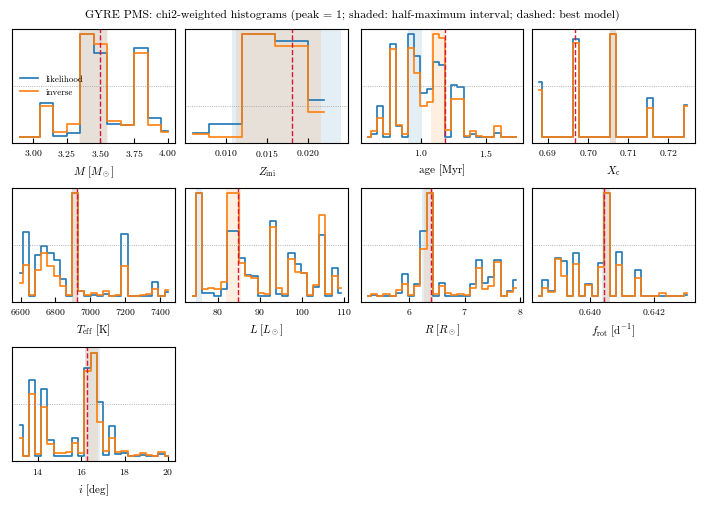

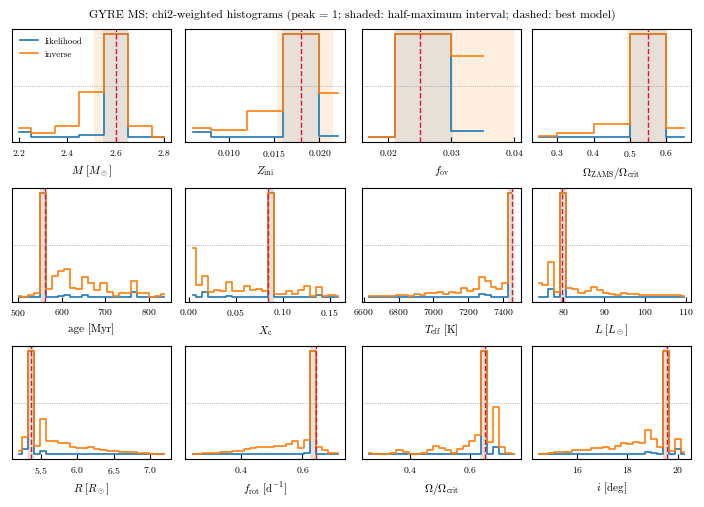

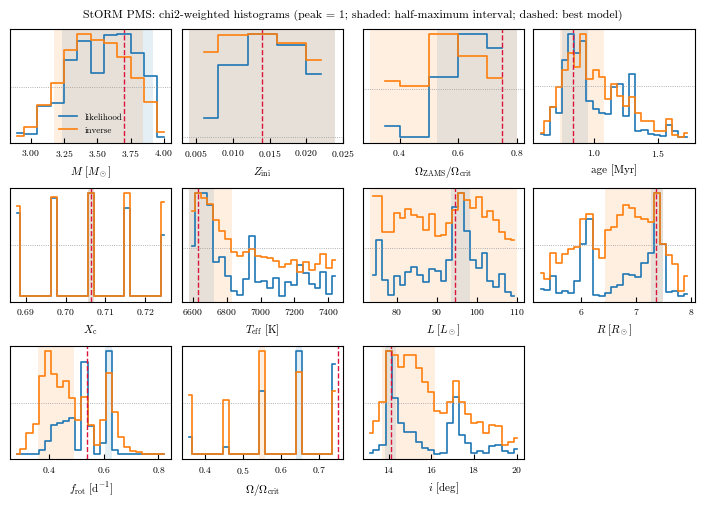

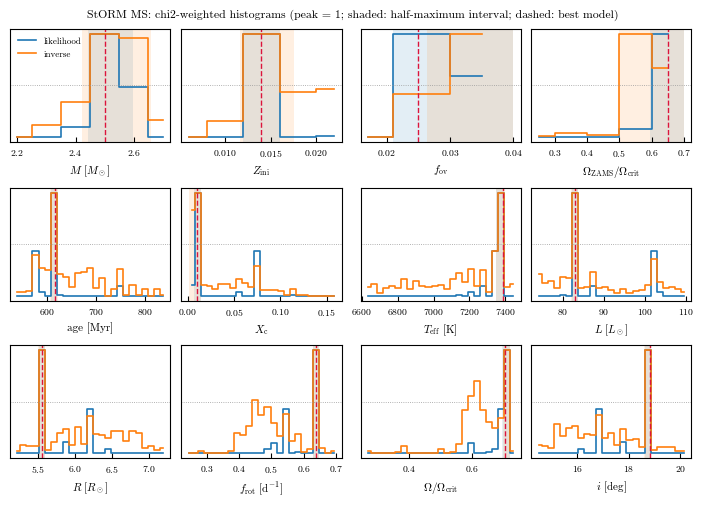

In [19]:
# ==========================================================================
# 6. Method 3: chi2-weighted histograms, half-maximum interval
# ==========================================================================
HIST_WEIGHTS = ("likelihood", "inverse")
HIST_BINS = 25               # continuous parameters: bins over the A1 + A2 range
HIST_PARAMS = ["star_mass", "Z", "fov", "omega", "age_Myr", "Xc", "Teff", "L",
               "R", "f_rot", OCRIT_COL, "incl_impl_deg"]
GRID_PARAMS = {"star_mass", "Z", "fov", "omega"}    # binned on grid values
HIST_COLS = {"likelihood": "tab:blue", "inverse": "tab:orange"}
PLABEL = {"star_mass": r"$M\ [M_\odot]$", "Z": r"$Z_{\rm ini}$",
          "fov": r"$f_{\rm ov}$", "omega": r"$\Omega_{\rm ZAMS}/\Omega_{\rm crit}$",
          "age_Myr": "age [Myr]", "Xc": r"$X_{\rm c}$",
          "Teff": r"$T_{\rm eff}$ [K]", "L": r"$L\ [L_\odot]$",
          "R": r"$R\ [R_\odot]$", "f_rot": r"$f_{\rm rot}$ [d$^{-1}$]",
          OCRIT_COL: r"$\Omega/\Omega_{\rm crit}$", "incl_impl_deg": r"$i$ [deg]"}


def chi2_weights(d, info, how):
    c = d["chi2"].to_numpy(float)
    cmin = info["chi2_min"]
    if how == "likelihood":
        w = np.exp(-0.5 * info["scale"] * (c - cmin))
    elif how == "inverse":
        w = cmin / c if cmin > 0 else (c == cmin).astype(float)
    else:
        raise ValueError(how)
    return w / w.sum()


def _bins(x, p):
    """(centres, edges) for parameter p: grid values or HIST_BINS bins."""
    if p in GRID_PARAMS:
        v = np.unique(x[np.isfinite(x)])
        if len(v) < 2:
            return None, None
        mid = 0.5 * (v[1:] + v[:-1])
        edges = np.r_[v[0] - (mid[0] - v[0]), mid, v[-1] + (v[-1] - mid[-1])]
        return v, edges
    lo, hi = np.nanmin(x), np.nanmax(x)
    if not hi > lo:
        return None, None
    edges = np.linspace(lo, hi, HIST_BINS + 1)
    return 0.5 * (edges[1:] + edges[:-1]), edges


def half_max(x, w, p):
    """(centres, h, peak, lo, hi, flag) of the weighted histogram of x."""
    cen, edges = _bins(x, p)
    if cen is None:
        return None
    ok = np.isfinite(x)
    h, _ = np.histogram(x[ok], bins=edges, weights=w[ok])
    k = int(np.argmax(h))
    half = 0.5 * h[k]

    def cross(step):
        i = k
        while 0 <= i + step < len(h) and h[i + step] >= half:
            i += step
        j = i + step
        if not 0 <= j < len(h):                  # still above half at the edge
            return (edges[0] if step < 0 else edges[-1]), "edge"
        f = (half - h[j]) / (h[i] - h[j])        # h[j] < half <= h[i]
        return cen[j] + f * (cen[i] - cen[j]), ""

    lo, fl = cross(-1)
    hi, fh = cross(+1)
    width = edges[1] - edges[0] if p not in GRID_PARAMS else np.inf
    flag = ",".join(s for s in (fl, fh) if s)
    if hi - lo <= 1.01 * width:
        flag = (flag + "," if flag else "") + "resolution-limited"
    return cen, h, cen[k], lo, hi, flag


HIST = {}
for how in HIST_WEIGHTS:
    ERR[f"hist_{how}"] = {}
for key, (d, info) in FIT.items():
    use = [p for p in HIST_PARAMS if p in d.columns
           and d[p].notna().any() and d[p].nunique() > 1]
    print(f"=== {NICE_A3.get(key, key)} ({info['n']:,} models)")
    for how in HIST_WEIGHTS:
        w = chi2_weights(d, info, how)
        n_eff = 1.0 / np.sum(w ** 2)
        res, lohi, rows = {}, {}, []
        for p in use:
            r = half_max(d[p].to_numpy(float), w, p)
            if r is None:
                continue
            res[p] = r
            lohi[p] = (r[3], r[4])
            rows.append({"param": p, "best": float(d[p].iloc[0]), "peak": r[2],
                         "lo": r[3], "hi": r[4], "FWHM": r[4] - r[3], "flag": r[5]})
        HIST[(key, how)] = res
        ERR[f"hist_{how}"][key] = _interval_table(d, lohi)
        print(f"  {how} weights: effective number of models {n_eff:.1f}")
        print(textwrap.indent(pd.DataFrame(rows).to_string(
            index=False, float_format=lambda x: f"{x:.4g}"), "    "))
    print()


def plot_hist(key, outfile=None):
    d, info = FIT[key]
    use = [p for p in HIST_PARAMS if all(p in HIST.get((key, h), {}) for h in HIST_WEIGHTS)]
    if not use:
        return
    ncol = 4
    nrow = int(np.ceil(len(use) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(17.6/2.54, 4.2 * nrow/2.54),
                             layout="constrained", squeeze=False)
    for ax, p in zip(axes.flat, use):
        for how in HIST_WEIGHTS:
            cen, h, pk, lo, hi, flag = HIST[(key, how)][p]
            c = HIST_COLS.get(how, "k")
            ax.step(cen, h / h.max(), where="mid", color=c, lw=1.2,
                    label=how if p == use[0] else None)
            ax.axvspan(lo, hi, color=c, alpha=0.12, lw=0)
        ax.axvline(float(d[p].iloc[0]), color="crimson", lw=1.0, ls="--")
        ax.axhline(0.5, color="0.6", lw=0.6, ls=":")
        ax.set_xlabel(PLABEL.get(p, p), fontsize=8)
        ax.set_yticks([])
        ax.tick_params(labelsize=7)
    for ax in list(axes.flat)[len(use):]:
        ax.set_axis_off()
    axes.flat[0].legend(fontsize=6.5, frameon=False)
    fig.suptitle(f"{NICE_A3.get(key, key)}: chi2-weighted histograms "
                 "(peak = 1; shaded: half-maximum interval; dashed: best model)",
                 fontsize=8.5)
    if outfile:
        for ext in ("pdf", "png"):
            fig.savefig(f"{outfile}.{ext}", dpi=200, bbox_inches="tight", pad_inches=0.02)
    plt.show()


for key in [k for row in GRID_2x2 for k in row if k in FIT]:
    plot_hist(key, f"hist_Fgrid_{key[0]}_{key[1]}")

## 6b. What the mode matching adds to A1 + A2

For each parameter and grid, the figure shows:

* **grey bar**: the range A1 + A2 alone leave, i.e. every model in the nominal box, with or without a candidate multiplet. For a static structure, $f_{\rm rot}$ is the union of its A2 windows. $i$ follows from each model's $R$ at the spectroscopic rotation rate.
* **coloured bar**: the Monte Carlo interval (`MC_Q` of the winners, section 5).
* **diamond**: the best model.

The tables give the same numbers, plus each interval's width as a fraction of the A1 + A2 width. They also list the Δχ² region (section 4) for reference; the figure leaves it out.

* For M, Z, f_ov and ω, a fraction of 0 means a single grid value: there the grid step is the resolution.
* The MC re-centres the box on every draw, so its T_eff, L and R can run past the nominal box. That is the spectroscopic error coming back in, not the frequencies loosening anything.

=== GYRE PMS: 491 A1 + A2 models, 24 in the region, 12 different MC winners
                best  A1A2 lo  A1A2 hi  region lo  region hi region/A1A2  MC lo  MC hi MC/A1A2
star_mass        3.5      2.9        4        3.1          4         82%      3    3.9     82%
Z              0.018    0.006    0.022      0.006      0.022        100%   0.01  0.022     75%
age_Myr        1.177   0.5642    1.752      0.644      1.594         80% 0.6302  1.635     85%
Xc            0.6967   0.6871   0.7255     0.6871     0.7255        100% 0.6871 0.7159     75%
Teff            6925     6578     7460       6589       7439         96%   6334   7231    102%
L              84.92    73.42      110      75.16      109.3         93%  65.24  122.3    156%
R              6.403    5.212    7.979      5.344      7.927         93%  5.147  8.058    105%
incl_impl_deg  16.28       13    20.14      13.09      19.62         91%  12.87  20.41    106%

=== StORM PMS: 2,937 A1 + A2 models, 295 in the region, 11 different

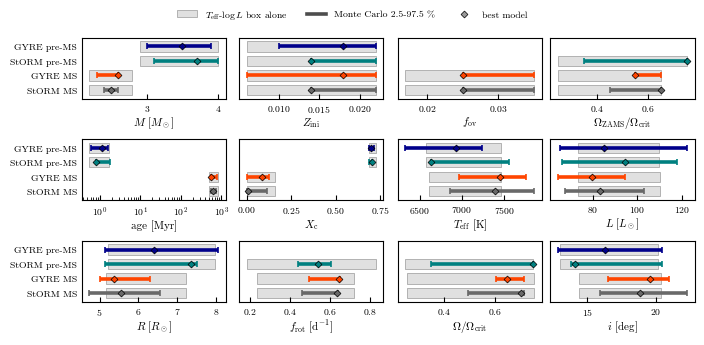

In [20]:
# ==========================================================================
# 6b. A1 + A2 alone against the Delta-chi2 region and the Monte Carlo
# ==========================================================================
# A12[key]: per parameter the A1 + A2 range, the region and the MC interval,
# each interval's width as a fraction of the A1 + A2 width. Same "--" cells
# as the LaTeX table: fov on the PMS, Omega of a static structure. The figure
# shows A1 + A2 and the MC only; the region is in the tables for reference.
from matplotlib.patches import Patch

A12_PARAMS = HIST_PARAMS     # labels: PLABEL (section 6)
# MS column of GRID_2x2 first, then PMS: the order of the LaTeX table
A12_ORDER = [r[j] for j in (0, 1) for r in GRID_2x2 if r[j] in ERR["mc"]]
X_PAD = 0.06                 # x margin, fraction of the span: no bar or cap cut off
A12_NCOL = 4                 # panels per row
A12_HEIGHT_CM = 8.5          # figure height; the width is the page, 17.6 cm
# no entry for a static (non-rotating) structure: no rotation in MESA, and
# its f_rot only floated inside the A2 window
STATIC_SKIP = ("omega", OCRIT_COL, "f_rot")


def _static(key):
    return not (FIT[key][0].iloc[0].get("f_rot_model_cpd", 0) > 0)


def a12_range(key, p):
    """(lo, hi) A1 + A2 alone leave for p: every model in the nominal box.
    Static structures: f_rot from their A2 windows."""
    m = BOX[key]
    if p == "f_rot":
        f = ([m["frot_lo"], m["frot_hi"]] if _static(key)
             else [m["f_rot_model_cpd"]])
        x = np.concatenate([np.asarray(v, float) for v in f])
    elif p == "incl_impl_deg":
        x = implied_incl_deg(m)
    elif p in m.columns:
        x = m[p].to_numpy(float)
    else:
        return np.nan, np.nan
    return np.nanmin(x), np.nanmax(x)


def _pct(x):
    return "--" if not np.isfinite(x) else f"{x:.0%}"


A12 = {}
for key in A12_ORDER:
    rows = {}
    for p in A12_PARAMS:
        if ((p == "fov" and key[1] == "PMS")
                or (p in STATIC_SKIP and _static(key))
                or p not in ERR["mc"][key].index or p not in ERR["region"][key].index):
            continue
        lo, hi = a12_range(key, p)
        r = {"best": ERR["mc"][key].loc[p, "best"], "A1A2 lo": lo, "A1A2 hi": hi}
        for name, meth in (("region", "region"), ("MC", "mc")):
            a, b = ERR[meth][key].loc[p, ["lo", "hi"]]
            r[f"{name} lo"], r[f"{name} hi"] = a, b
            r[f"{name}/A1A2"] = (b - a) / (hi - lo) if hi > lo else np.nan
        rows[p] = r
    A12[key] = pd.DataFrame.from_dict(rows, orient="index")
    print(f"=== {NICE_A3.get(key, key)}: {len(BOX[key]):,} A1 + A2 models, "
          f"{FIT[key][1]['n_region']:,} in the region, "
          f"{MC[key].apply(model_label, axis=1).nunique():,} different MC winners")
    print(A12[key].to_string(float_format=lambda x: f"{x:.4g}",
                             formatters={c: _pct for c in ("region/A1A2", "MC/A1A2")}))
    print()

_ps = [p for p in A12_PARAMS if any(p in A12[k].index for k in A12_ORDER)]
for name in ("MC", "region"):
    t = pd.DataFrame({NICE_A3.get(k, k): A12[k][f"{name}/A1A2"]
                      for k in A12_ORDER}).reindex(_ps)
    print(f"{name} interval width / A1 + A2 width"
          + (f" (MC {100 * MC_Q[0]:g}-{100 * MC_Q[1]:g} %)" if name == "MC" else ""))
    print(t.to_string(formatters={c: _pct for c in t.columns}, na_rep="--"))
    print()


def _set_xlim(ax, vals, log=False):
    """x range over every plotted value, padded by X_PAD (in log on a log axis)."""
    v = np.asarray(vals, float)
    v = v[np.isfinite(v)]
    if log:
        v = np.log10(v)
    lo, hi = v.min(), v.max()
    pad = X_PAD * (hi - lo) if hi > lo else 0.05 * max(abs(lo), 1.0)
    lo, hi = lo - pad, hi + pad
    ax.set_xlim(*((10 ** lo, 10 ** hi) if log else (lo, hi)))


def plot_a12(outfile):
    ncol = A12_NCOL
    nrow = -(-len(_ps) // ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(17.6 / 2.54, A12_HEIGHT_CM / 2.54),
                             layout="constrained", squeeze=False)
    ys = np.arange(len(A12_ORDER))[::-1]           # first grid on top
    for k, (ax, p) in enumerate(zip(axes.flat, _ps)):
        vals = []
        for y, key in zip(ys, A12_ORDER):
            if p not in A12[key].index:
                continue
            r, c = A12[key].loc[p], COLS_A3.get(key, "0.3")
            ax.barh(y, r["A1A2 hi"] - r["A1A2 lo"], left=r["A1A2 lo"], height=0.72,
                    color="0.88", ec="0.6", lw=0.5, zorder=1)
            ax.errorbar(0.5 * (r["MC lo"] + r["MC hi"]), y,
                        xerr=0.5 * (r["MC hi"] - r["MC lo"]), fmt="none", ecolor=c,
                        elinewidth=2.6, capsize=2.5, capthick=1.2, zorder=3)
            ax.plot(r["best"], y, "D", ms=3.5, color=c, mec="k", mew=0.5, zorder=4)
            vals += [r["A1A2 lo"], r["A1A2 hi"], r["MC lo"], r["MC hi"], r["best"]]
        if p == "age_Myr":                         # PMS ~1 Myr, MS ~600 Myr
            ax.set_xscale("log")
        _set_xlim(ax, vals, log=p == "age_Myr")
        ax.set_yticks(ys)
        ax.set_yticklabels([NICE_A3.get(key, key).replace("PMS", "pre-MS")
                            for key in A12_ORDER]
                           if k % ncol == 0 else [])
        ax.tick_params(axis="y", length=0, labelsize=7)
        ax.tick_params(axis="x", labelsize=7)
        ax.set_ylim(-0.6, len(A12_ORDER) - 0.4)
        ax.set_xlabel(PLABEL.get(p, p), fontsize=8, labelpad=1)
    for ax in list(axes.flat)[len(_ps):]:
        ax.set_axis_off()
    handles = [Patch(fc="0.88", ec="0.6", lw=0.5, label=r"$T_{\rm eff}$-$\log L$ box alone"),
               Line2D([], [], color="0.3", lw=2.6,
                      label=f"Monte Carlo {100 * MC_Q[0]:g}-{100 * MC_Q[1]:g} %")]
    handles.append(Line2D([], [], marker="D", ls="none", ms=3.5, color="0.6",
                          mec="k", mew=0.5, label="best model"))
    fig.legend(handles=handles, loc="outside upper center", ncol=len(handles), fontsize=7,
               frameon=False)
    for ext in ("pdf", "png"):
        fig.savefig(f"{outfile}.{ext}", dpi=200)   # no crop: exactly figsize
    plt.show()


plot_a12("a1a2_vs_matching_Fgrid")

## 7. LaTeX table

In [21]:
# ==========================================================================
# 7. LaTeX table tab:ModelBestFits
# ==========================================================================
# Prints the whole table for the paper. Columns: grid, phase; the free parameters
# of the fit M, Z, omega, fov, age; a vertical rule; the derived R, L, Teff, Xc,
# f_rot (headed f_surf), i, rms(F - F_obs). Every value is the best F_grid model,
# Xc and f_rot at 3 significant figures, and the rms has no error; the errors are
# best - lo and hi - best of TEX_METHOD's interval, clipped at zero where the best
# model lies outside it. "---": fov on the PMS (no core yet; the fov copies were
# collapsed), omega of a static GYRE PMS structure.
# Its f_rot carries footnote (a): profiled inside the A2 window, not a model
# property. A grid with nothing in FIT gets NO_MODEL_TEX, printed as a LaTeX comment.
TEX_METHOD = "mc"            # key of ERR: whose errors the table shows
GRID_TEX = {("GYRE_MESA", "PMS"): ("GYRE",     "PMS"),
            ("STORM", "PMS"):     ("StORM",     "PMS"),
            ("INNSBRUCK", "PMS"): ("Steindl", "PMS"),
            ("GYRE_MESA", "MS"):  ("GYRE",     "MS"),
            ("STORM", "MS"):      ("StORM",     "MS")}
TEX_COLS = [("star_mass", 1), ("Z", 3), ("omega", 2), ("fov", 3), ("age_Myr", None),
            ("R", 2), ("L", 1), ("Teff", 0), ("Xc", None), ("f_rot", None), ("incl_impl_deg", 1)]
NO_MODEL_TEX = (r"\multicolumn{12}{c}{no model within $1.96\sigma$ of "
                r"$T_{\rm eff}$ and $L$}")
TEX_TOP = r"""\begin{table*}[t]
\centering
\small
\renewcommand{\arraystretch}{1.2}
\tabcolsep=1pt
\renewcommand{\arraystretch}{1.35}
\caption{Asteroseismic parameter estimates ($\theta$, left) and inferred parameters (right) from the best-fitting model of HD\,35929 in each grid, where M stands for MESA, G for GYRE and S for StORM in the grid column. We list first the free parameters \(\bm \theta\) of the merit function and resulting relevant parameters. Only models within $1.96\sigma$ of the observed spectroscopic $T_{\rm eff}$ and astrometric $L$ and rotation consistent with the spectroscopic \(v\sin i\) are considered. The rotation frequency of each model must be compatible, for that model's radius, with $v\sin i$ and the inclination of \citet{RensPaper2025} following Sec.\,\ref{sec:ModelMatching}. Errors are the 2.5-97.5\,\% range from an MC approach (see Fig.\,\ref{fig:BoxMatchingParameters} for visualisation). The inclination $i$ follows from the seismic estimate of $R$, from the photometric surface rotation rate \(f_{\rm rot}\) and from the central value of $v\sin i$, so its uncertainty excludes that of $v\sin i$. The last column gives the rms difference between the frequencies of the best-fitting model and the three observed ones.}
\footnotesize
\begin{tabular*}{\textwidth}{@{\extracolsep{\fill}}
ll|ccccc@{\hspace{2.5pt}}|@{\hspace{2.5pt}}ccccccc}
\hline
Grid & Phase & $M_{\rm ini}$ & $Z_{\rm ini}$ & $\Omega_{\rm ini}/\Omega_{\rm crit}$ & $f_{\rm ov}$ & Age & Radius & $L$ & $T_{\rm eff}$ & $X_c$ & $f_{\rm surf}$ & $i$ & rms \\
 & & [$M_{\odot}$] & & & & [Myr] & [$R_{\odot}$] & [$L_{\odot}$] & [K] & & [d$^{-1}$] & [deg] & [d$^{-1}$] \\
\hline\hline"""
TEX_BOTTOM = r"""\hline
\end{tabular*}
\tablefoot{
\tablefoottext{a}{Non-rotating structure (rotation enters this grid only at the
ZAMS). $f_{\rm rot}$ is the value that reproduces the observed splitting with the
model's own Ledoux constant, $f_{\rm rot} = \delta\nu/(1 - C_{n\ell})$.}
}
\label{tab:ModelBestFits}
\end{table*}"""


def tex_nd(p, x, nd):
    """Decimals of column p at value x: nd, or by value for the columns without one."""
    if p == "age_Myr":
        return 2 if x < 10 else 1
    if p in ("Xc", "f_rot"):       # 3 significant figures
        return 2 - int(f"{x:.2e}".split("e")[1])
    return nd


def tex_pm(best, lo, hi, nd):
    """$best^{+up}_{-dn}$; $best$ alone without an interval or if both errors round to 0."""
    v = f"{best:.{nd}f}"
    if not (np.isfinite(lo) and np.isfinite(hi)):
        return f"${v}$"
    up, dn = max(hi - best, 0.0), max(best - lo, 0.0)
    su, sd = f"{up:.{nd}f}", f"{dn:.{nd}f}"
    if float(su) == 0 and float(sd) == 0:
        return f"${v}$"
    return f"${v}^{{+{su}}}_{{-{sd}}}$"


def tex_row(key, method):
    grid, phase = GRID_TEX[key]
    b = FIT[key][0].iloc[0]
    e = ERR[method].get(key)
    static = not (b.get("f_rot_model_cpd", 0) > 0)
    cells = [grid, phase]
    for p, nd in TEX_COLS:
        if (p == "fov" and phase == "PMS") or (p == "omega" and static):
            cells.append("---")
            continue
        x = float(b[p])
        if not np.isfinite(x):
            cells.append("---")
            continue
        nd = tex_nd(p, x, nd)
        lo, hi = ((e.loc[p, "lo"], e.loc[p, "hi"])
                  if e is not None and p in e.index else (np.nan, np.nan))
        s = tex_pm(x, lo, hi, nd)
        if p == "f_rot" and static:
            s += r"\tablefootmark{(a)}"
        cells.append(s)
    cells.append(f"${np.sqrt(((b[F_IDS].to_numpy(float) - F_OBS) ** 2).mean()):.4f}$")
    return " & ".join(cells) + r" \\"


print(TEX_TOP)
for key, (grid, phase) in GRID_TEX.items():
    if key in FIT:
        print(tex_row(key, TEX_METHOD))
    else:
        print(f"% {grid} & {phase} & {NO_MODEL_TEX} \\\\")
print(TEX_BOTTOM)

\begin{table*}[t]
\centering
\small
\renewcommand{\arraystretch}{1.2}
\tabcolsep=1pt
\renewcommand{\arraystretch}{1.35}
\caption{Asteroseismic parameter estimates ($\theta$, left) and inferred parameters (right) from the best-fitting model of HD\,35929 in each grid, where M stands for MESA, G for GYRE and S for StORM in the grid column. We list first the free parameters \(\bm \theta\) of the merit function and resulting relevant parameters. Only models within $1.96\sigma$ of the observed spectroscopic $T_{\rm eff}$ and astrometric $L$ and rotation consistent with the spectroscopic \(v\sin i\) are considered. The rotation frequency of each model must be compatible, for that model's radius, with $v\sin i$ and the inclination of \citet{RensPaper2025} following Sec.\,\ref{sec:ModelMatching}. Errors are the 2.5-97.5\,\% range from an MC approach (see Fig.\,\ref{fig:BoxMatchingParameters} for visualisation). The inclination $i$ follows from the seismic estimate of $R$, from the photometric s

## 8. Model multiplet against the observed frequencies

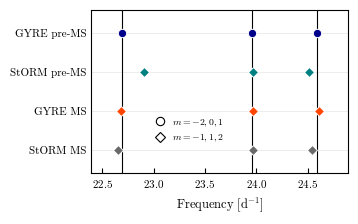

GYRE PMS M3.5_Z0.018_omega0.00_fov0.005 profile 209           (-2, 0, 1)  F - f_obs [-0.38 -1.05 -0.22] 1e-3 d^-1
StORM PMS M3.7_Z0.014_omega0.00_fov0.005 profile 203 rot 0.75  (-1, 1, 2)  F - f_obs [212.56  10.79 -82.42] 1e-3 d^-1
GYRE MS  M2.6_Z0.018_omega0.55_fov0.025 profile 345           (-1, 1, 2)  F - f_obs [-7.37  5.2  12.64] 1e-3 d^-1
StORM MS M2.5_Z0.014_omega0.65_fov0.025 profile 359           (-1, 1, 2)  F - f_obs [-37.58   7.68 -52.49] 1e-3 d^-1


In [22]:
# ==========================================================================
# 8. Best model's multiplet against the observed frequencies, one panel
# ==========================================================================
# One row per grid, in the order of the LaTeX table. GYRE: the assigned
# members of the exactly linear multiplet (static PMS structures at the f_rot
# profiled inside their A2 window); StORM: its three matched modes (PMS at the
# rate StORM imposed). Vertical lines: the observed F1..F3. Marker shape: the
# m-assignment. Below the plot: model - observed for every member.
QUINT_ROWS = [("GYRE_MESA", "PMS"), ("STORM", "PMS"), ("GYRE_MESA", "MS"), ("STORM", "MS")]
QUINT_MARKERS = {(-2, 0, 1): ("o", 6.0), (-1, 1, 2): ("D", 5.0)}   # shape, size [pt]
QUINT_PAD = 0.3                            # d^-1 either side of the observed frequencies
QUINT_FIGSIZE = (8.8 / 2.54, 5.4 / 2.54)   # one A&A column


def plot_quintuplets_best(outfile):
    fig, ax = plt.subplots(figsize=QUINT_FIGSIZE)
    ys = np.arange(len(QUINT_ROWS))[::-1]            # first grid at the top
    for fv in F_OBS:
        ax.axvline(fv, color="k", lw=0.8, zorder=1)
    for y, key in zip(ys, QUINT_ROWS):
        if key not in FIT:
            ax.text(F_OBS.mean(), y, "no model survives A1 + A2", ha="center",
                    va="center", fontsize=7, color="0.35")
            continue
        b = FIT[key][0].iloc[0]
        f, ms_, recon = multiplet_lines(b)
        asg = tuple(_asg(b.assignment))
        fm = np.array([fv for m, fv in zip(ms_, f) if m in asg]) if recon else f
        mk, sz = QUINT_MARKERS[asg]
        ax.plot(fm, np.full(len(fm), y), ls="none", marker=mk, ms=sz,
                color=COLS_A3.get(key, "0.3"), mec="white", mew=0.7, zorder=3)
    ax.set_yticks(ys, [f"{GRID_TEX[k][0]} {'pre-MS' if k[1] == 'PMS' else 'MS'}"
                       for k in QUINT_ROWS])
    ax.set_ylim(ys.min() - 0.6, ys.max() + 0.6)
    ax.grid(axis="y", color="0.9", lw=0.5)
    ax.set_axisbelow(True)
    ax.set_xlim(F_OBS.min() - QUINT_PAD, F_OBS.max() + QUINT_PAD)
    ax.set_xlabel(r"Frequency [$\mathrm{d}^{-1}$]", fontsize=9)
    ax.tick_params(labelsize=8)
    ax.tick_params(axis="y", length=0)
    # top = ax.secondary_xaxis("top")
    # top.set_xticks(F_OBS, [f"$F_{{{k[1:]}}}$" for k in F_IDS])
    # top.tick_params(labelsize=8, length=0)
    # the shapes, in the widest gap between observed frequencies, between the lowest two rows
    gap = int(np.argmax(np.diff(F_OBS)))
    handles = [plt.Line2D([], [], ls="none", marker=mk, ms=sz, mfc="white", mec="k",
                          mew=0.8, label=rf"$m = {', '.join(str(m) for m in asg)}$")
               for asg, (mk, sz) in QUINT_MARKERS.items()]
    ax.legend(handles=handles, loc="center", fontsize=7, frameon=False,
              bbox_to_anchor=((F_OBS[gap] + F_OBS[gap + 1]) / 2, ys.min() + 0.5),
              bbox_transform=ax.transData, handletextpad=0.3, labelspacing=0.4)
    fig.tight_layout(pad=0.3)
    for ext in ("pdf", "png"):
        plt.savefig(f"{outfile}.{ext}", dpi=300)
    plt.show()

    for key in [k for k in QUINT_ROWS if k in FIT]:
        b = FIT[key][0].iloc[0]
        f, ms_, recon = multiplet_lines(b)
        asg = _asg(b.assignment)
        fm = np.array([fv for m, fv in zip(ms_, f) if m in asg]) if recon else f
        print(f"{' '.join(GRID_TEX[key]):<8} {model_label(b):<52} {b.assignment}  "
              f"F - f_obs {np.round(1e3 * (fm - F_OBS), 2)} 1e-3 d^-1")


plot_quintuplets_best("quintuplet_Fgrid")

## 9. Splitting kernels of the best models

The grids kept summary output only, so each best model's eigenfunctions were rerun. The first cell lists the best `F_grid` model per grid, the modes its kernel needs, and whether the rerun output is on disk. The search uses `ROOT["gyre_detail"]` and `ROOT["storm_eigen"]`, which on `MACHINE = "windows"` are both the `ForwardModelling` folder:

* **GYRE** (`rerun_gyre_best.py` on STER): `<track>_profile<N>/detail.l2.m+0.n+<n_pg>.h5`, the $\ell$ = `P_L`, $m = 0$ mode at the fitted $n_{\rm pg}$.
* **StORM** (on VSC): `<track>/profile<N>_even.hdf5`, or `profile<N>_rot<rot>_even.hdf5` on the PMS.
* **MESA profiles**: `profile<N>.data` and `profile<N>.data.GYRE` in the same folder as the rerun. The `LOGS` of the track are only tried if they are not there.

If the best model changes, the first cell prints the rerun commands for the new one. Run them and copy the outputs and the two MESA files to the layout above. Panels whose files are missing show the error instead of failing.

In [61]:
# ==========================================================================
# 9. Best models -> eigenfunction reruns for the kernel figure
# ==========================================================================
KERNEL_CASE = "F_grid"       # label only: this notebook fits one case

GYRE_DETAIL_ROOT = ROOT["gyre_detail"]
STORM_EIGEN_ROOT = ROOT["storm_eigen"]
STORM_BATCHES    = ROOT["ster"] / "storm_grid" / "unpacked"
STORM_PMS_BATCH  = "pms_box_A1_full_M2.9-M3.9"     # VSC tag of the StORM PMS runs
MESA_GRID_ROOTS  = (ROOT["ster"] / "mesa_grid" / "grid_runs",
                    ROOT["ster"] / "mesa_grid" / "grid_runs_pms_ext")
# printed for STER, so always the STER paths
GYRE_RERUN_CMD = (
    "python3 /STER/kianTedeskino/HD35929/gyre_grid/rerun_gyre_best.py "
    "--track {track} --profile {profile} --n {n} --l {l} "
    "--gyre /home/r1082832/Codes/mesa-24.08.1/gyre-8.1/bin/gyre "
    "--template /home/r1082832/ConnyProj/GYRE_grid/gyre_ad_p-modes.in "
    "--out /STER/kianTedeskino/HD35929/gyre_grid/gyre_best_rerun")


def track_logs(track):
    """LOGS directory of a MESA track: main grid first, then the PMS extension."""
    for root in MESA_GRID_ROOTS:
        d = root / str(track) / "LOGS"
        if d.is_dir():
            return d
    raise FileNotFoundError(f"{track}: no LOGS under "
                            + " or ".join(str(r) for r in MESA_GRID_ROOTS))


def gyre_detail_dir(track, profile):
    return GYRE_DETAIL_ROOT / f"{track}_profile{int(profile)}"


def gyre_detail_file(track, profile, n, l=P_L):
    """File name rerun_gyre_best.py writes (detail.l%l.m%m.n%n.h5)."""
    return gyre_detail_dir(track, profile) / f"detail.l{l}.m+0.n{int(n):+d}.h5"


def profile_file(track, profile, suffix=".data"):
    """MESA profile<N><suffix>: next to the model's reruns, else in its LOGS."""
    name = f"profile{int(profile)}{suffix}"
    for d in (gyre_detail_dir(track, profile), STORM_EIGEN_ROOT / str(track)):
        if (d / name).exists():
            return d / name
    return track_logs(track) / name


def storm_eigen_file(track, profile, rot=None):
    """StORM output with eigenfunctions; rot only for a PMS run. In
    <batch>/<track>/ on STER, directly in <track>/ in the local folder."""
    name = (f"profile{int(profile)}_even.hdf5" if rot is None
            else f"profile{int(profile)}_rot{rot:.2f}_even.hdf5")
    hits = sorted([*STORM_EIGEN_ROOT.glob(f"*/{track}/{name}"),
                   *STORM_EIGEN_ROOT.glob(f"{track}/{name}")])
    return hits[0] if hits else None


def storm_batch(track, rot=None):
    """VSC batch of a track from its mass, e.g. batch3_M2.4-M2.6. The PMS
    runs (rot given) are one batch of their own."""
    if rot is not None:
        return STORM_PMS_BATCH
    M = float(re.match(r"M([\d.]+)_", str(track))[1])
    for d in sorted(STORM_BATCHES.glob("batch*_M*-M*")):
        lo, hi = map(float, re.search(r"_M([\d.]+)-M([\d.]+)$", d.name).groups())
        if lo - 1e-6 <= M <= hi + 1e-6:
            return d.name
    return "batch ?"


def is_pms_ext(track):
    """True for a track of the PMS-only extension; None if its LOGS are not
    reachable from this machine."""
    try:
        return track_logs(track).parents[1] == MESA_GRID_ROOTS[1]
    except FileNotFoundError:
        return None


_storm_inv = {}

def storm_members(b):
    """(m, freq, l, n_pg, dom_frac) of the three matched modes of a StORM row."""
    tid, prof, rot = str(b.track_id), int(b.profile), pms_rot(b)
    if (tid, prof, rot) not in _storm_inv:
        t = pq.read_table(STORM_MODES_PARQUET,
                          columns=["track_id", "profile", "rot", "m", "l",
                                   "n_pg", "freq_d", "dom_frac"],
                          filters=(pc.field("profile") == prof)).to_pandas()
        t = t[t.track_id.astype(str) == tid]
        if rot is not None:                  # PMS: only this rot run
            t = t[np.isclose(t.rot, rot)]
        _storm_inv[(tid, prof, rot)] = t
    t = _storm_inv[(tid, prof, rot)]
    out = []
    for m_, f_ in zip(_asg(b.assignment), (b.f0, b.f1, b.f2)):
        r = t[(t.m == m_) & np.isclose(t.freq_d, f_, atol=1e-6)]
        out.append((m_, f_) + ((int(r.l.iloc[0]), int(r.n_pg.iloc[0]),
                                float(r.dom_frac.iloc[0])) if len(r)
                               else (-1, -1, np.nan)))
    return out


def kernel_reruns(fits):
    """Best model per grid, the reruns its kernel needs and whether they are
    on disk. Returns the best model per grid."""
    models, todo_gyre, todo_storm = {}, {}, {}
    for key in [k for row in GRID_2x2 for k in row]:
        print(f"=== {NICE_A3.get(key, key)} ===")
        if key not in fits:
            print("  no fit for this grid\n")
            continue
        b = fits[key][0].iloc[0]
        models[key] = b
        tid, prof = str(b.track_id), int(b.profile)
        if key[0] == "STORM":
            rot = pms_rot(b)
            f = storm_eigen_file(tid, prof, rot)
            print(f"  {model_label(b)}   "
                  + (f"on disk ({f.name})" if f
                     else f"{storm_batch(tid, rot)}   MISSING"))
            for m_, f_, l_, n_, dom in storm_members(b):
                print(f"    m={m_:+d}  f={f_:.5f} d^-1   l={l_}  n_pg={n_}   "
                      f"dom_frac {dom:.2f}")
            if f is None:
                todo_storm[(tid, prof, rot)] = storm_batch(tid, rot)
        else:
            n = int(b.n_best)
            ok = gyre_detail_file(tid, prof, n).exists()
            ext = None if ok else is_pms_ext(tid)    # only matters for a rerun
            print(f"  {tid}  profile {prof}   l={P_L}  m=+0  n_pg={n}   "
                  f"{'on disk' if ok else 'MISSING'}"
                  + ("   (PMS-ext track)" if ext else "")
                  + ("   (LOGS not reachable here)" if ext is None and not ok else ""))
            if not ok:
                todo_gyre.setdefault((tid, prof), set()).add(n)
        print()

    # one run per profile: rerun_gyre_best.py writes n +- n_pad (default 2)
    print(f"--- GYRE reruns on STER ({len(todo_gyre)}) ---")
    for (tid, prof), ns in todo_gyre.items():
        n0 = (min(ns) + max(ns)) // 2
        pad = max(2, max(ns) - n0, n0 - min(ns))
        print(GYRE_RERUN_CMD.format(track=tid, profile=prof, n=n0, l=P_L)
              + (f" --n-pad {pad}" if pad > 2 else ""))
        if is_pms_ext(tid):
            print("  ^ PMS-ext track: rerun_gyre_best.py reads grid_runs only "
                  "(its GRID_ROOT); the profiles are in grid_runs_pms_ext")
    if not todo_gyre:
        print("nothing missing")
    print(f"\n--- StORM reruns on VSC, eigenfunctions on ({len(todo_storm)}) ---")
    print("\n".join(f"{bt}  {tid}  profile {prof}"
                    + ("" if rot is None else f"  rot {rot:.2f}")
                    for (tid, prof, rot), bt in todo_storm.items())
          or "nothing missing")
    return models


KERNEL_MODELS = kernel_reruns(FIT)

=== GYRE PMS ===
  M3.5_Z0.018_omega0.00_fov0.005  profile 209   l=2  m=+0  n_pg=17   on disk

=== GYRE MS ===
  M2.6_Z0.018_omega0.55_fov0.025  profile 345   l=2  m=+0  n_pg=15   on disk

=== StORM PMS ===
  M3.7_Z0.014_omega0.00_fov0.005 profile 203 rot 0.75   on disk (profile203_rot0.75_even.hdf5)
    m=-1  f=22.90367 d^-1   l=2  n_pg=21   dom_frac 0.29
    m=+1  f=23.97176 d^-1   l=2  n_pg=21   dom_frac 0.29
    m=+2  f=24.51232 d^-1   l=2  n_pg=21   dom_frac 0.14

=== StORM MS ===
  M2.5_Z0.014_omega0.65_fov0.025 profile 359   on disk (profile359_even.hdf5)
    m=-1  f=22.65353 d^-1   l=2  n_pg=16   dom_frac 0.19
    m=+1  f=23.96865 d^-1   l=2  n_pg=16   dom_frac 0.18
    m=+2  f=24.54225 d^-1   l=2  n_pg=16   dom_frac 0.18

--- GYRE reruns on STER (0) ---
nothing missing

--- StORM reruns on VSC, eigenfunctions on (0) ---
nothing missing


=== GYRE PMS: M3.5_Z0.018_omega0.00_fov0.005  profile 209 ===
  C:\Users\Kian\Desktop\Uni\KU Leuven\ConnyProj\Pipelines+Data\ForwardModelling\M3.5_Z0.018_omega0.00_fov0.005_profile209
  detail.l2.m+0.n+17.h5, density from GYRE rho, 1720 points
=== GYRE MS: M2.6_Z0.018_omega0.55_fov0.025  profile 345 ===
  C:\Users\Kian\Desktop\Uni\KU Leuven\ConnyProj\Pipelines+Data\ForwardModelling\M2.6_Z0.018_omega0.55_fov0.025_profile345
  detail.l2.m+0.n+15.h5, density from GYRE rho, 2501 points
=== StORM PMS: M3.7_Z0.014_omega0.00_fov0.005  profile 203  rot 0.75 ===
  C:\Users\Kian\Desktop\Uni\KU Leuven\ConnyProj\Pipelines+Data\ForwardModelling\M3.7_Z0.014_omega0.00_fov0.005\profile203_rot0.75_even.hdf5
  density from profile203.data.GYRE, 1675 points to r/R = 1.00146
  m=-1: deformed 22.90367 (target 22.90367), inertia by l: l2 0.68, l4 0.32 (from |v|^2: l2 0.68, l4 0.32); dominant basis l=2 n_pg=21 (0.29); basis inertia max/min 1.00
  m=+1: deformed 23.97176 (target 23.97176), inertia by l: l2 0.

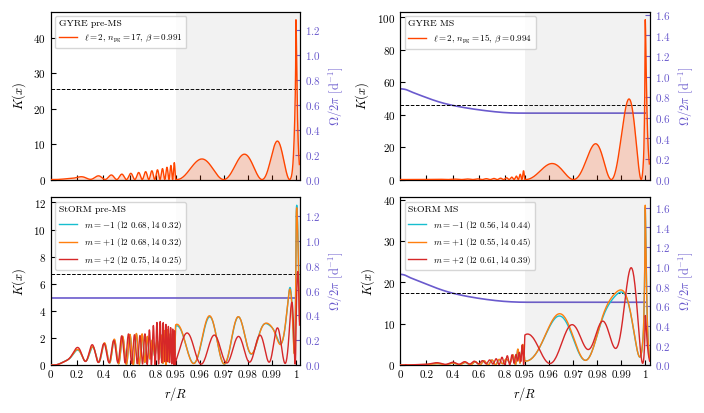


grid           m     beta  grid beta  Om_surf   Om_eff  eff/surf   x_50   x_peak  in zoom
GYRE PMS      +0   0.9909     0.9909      nan      nan       nan  0.803   1.0000    0.227
GYRE MS       +0   0.9943     0.9943   0.6449   0.6510    1.0095  0.979   1.0000    0.687
StORM PMS     -1   0.9792        nan   0.5385   0.5385    1.0000  0.654   1.0003    0.122
StORM PMS     +1   1.0012        nan   0.5385   0.5385    1.0000  0.653   1.0003    0.119
StORM PMS     +2   1.0117        nan   0.5385   0.5385    1.0000  0.639   1.0007    0.074
StORM MS      -1   0.9738        nan   0.6382   0.6546    1.0256  0.936   1.0000    0.459
StORM MS      +1   1.0047        nan   0.6382   0.6546    1.0257  0.936   1.0000    0.459
StORM MS      +2   1.0128        nan   0.6382   0.6625    1.0380  0.903   0.9941    0.376


In [62]:
# ==========================================================================
# 9. SPLITTING KERNELS OF THE BEST MODELS   (needs KERNEL_MODELS, cell above)
# ==========================================================================
# 2 x 2 like the multiplet figure (GRID_2x2): GYRE top, StORM bottom, PMS
# left, MS right, each for the section-8 best model the cell above picked
# (KERNEL_CASE):
#   GYRE      K(x) of the l = P_L, m = 0 mode at the fitted n_pg
#   StORM     K(x) of each matched deformed mode, built from its basis-mode
#             eigenfunctions (see storm_kernel)
# Rotating models also get Omega(r) on a twin axis and Omega_eff =
# int K Omega dx / beta in the summary: from the MESA profile on the MS, the
# uniform rate StORM imposed on the PMS. Every panel, the static GYRE PMS one
# too, has the twin axis with the observed surface rate F_ROT_CPD (dashed).
#
# The zoom on the envelope happens inside each panel: the x axis is piecewise
# linear, the bulk (r/R < 1 - KERNEL_ZOOM) squeezed into the left
# 1 - KERNEL_ZOOM_FRAC of the panel and the outer KERNEL_ZOOM of the radius
# (shaded) stretched over the rest. All panels share one x axis, up to the
# largest r/R of the four, so the others end just short of it. The eigenfunction
# grid runs ~0.2 % further, through the atmosphere the pulse file adds above the
# photosphere (tau = 2/3 to 1e-3), and beta and the summary use all of it.
# Dashed = where K peaks (off the panel if that is above R). In the summary,
# 'x_peak' is where K is largest and 'in zoom' the fraction of beta from inside
# the shaded part.
#
# StORM density comes from the .GYRE pulse file StORM was run on, whose grid
# IS StORM's radial-coordinate. The MESA profile stops at r = R and cannot
# give the atmosphere points.
#
# Paths are derived from KERNEL_MODELS. To plot any other model, put its path
# in KERNEL_OVERRIDE; track, profile and rot are then read from the path.
# The override applies to every call of plot_kernels (section 9 reuses it).
import re
import textwrap
import h5py
from pathlib import Path

KERNEL_ZOOM      = 0.05     # outer r/R stretched inside each panel; None = linear axis
KERNEL_ZOOM_FRAC = 0.5      # share of the panel width that outer part gets
STORM_FREQ_TOL = 1e-3       # d^-1; the right file reproduces its own modes to ~1e-5
STORM_EV_AXIS  = "col"      # "row": eigenvector[i] belongs to deformed mode i,
                            # as ingest_storm.py assumed. See the check printed below.

KERNEL_OVERRIDE = {
    # ("GYRE_MESA", "MS"): dict(path="/STER/.../gyre_best_rerun/<track>_profile<N>", n=<n_pg>),
    # ("STORM", "MS"):     dict(path="/STER/.../<batch>/<track>/profile<N>_even.hdf5",
    #                           freqs={-1: 22.6535, 1: 23.9687, 2: 24.5422}),
    # ("STORM", "PMS"):    dict(path="/STER/.../<batch>/<track>/profile<N>_rot<rot>_even.hdf5",
    #                           freqs={...}, omega_cd=0.55),
}


# --- small helpers ------------------------------------------------------------
def _re(a):
    a = np.asarray(a)
    if a.dtype.names and "re" in a.dtype.names:
        return np.asarray(a["re"], float)
    return np.real(a).astype(float)


def _abs2(a):
    a = np.asarray(a)
    if a.dtype.names and "re" in a.dtype.names:
        return a["re"] ** 2 + a["im"] ** 2
    return np.abs(a) ** 2


def _int(y, x):
    return np.trapezoid(y, x) if hasattr(np, "trapezoid") else np.trapz(y, x)


def _get(h, k, default=None):
    """GYRE stores scalars (l, m, n_pg) as attributes, arrays as datasets."""
    if k in h.attrs:
        return h.attrs[k]
    if k in h:
        return h[k][...]
    return default


def mesa_profile(track, profile):
    """x = r/R ascending, rho (or None), Omega/2pi in d^-1 (zeros if absent)."""
    f = profile_file(track, profile, ".data")
    with open(f) as fh:
        for _ in range(5):
            fh.readline()
        head = fh.readline().split()
    p = pd.read_csv(f, sep=r"\s+", skiprows=5, header=0,
                    usecols=[c for c in ("radius", "logR", "logRho", "omega")
                             if c in head])
    r = p["radius"].to_numpy(float) if "radius" in p \
        else 10 ** p["logR"].to_numpy(float)
    o = np.argsort(r)
    x = r[o] / r.max()
    rho = 10 ** p["logRho"].to_numpy(float)[o] if "logRho" in p else None
    om = (p["omega"].to_numpy(float)[o] * 86400 / (2 * np.pi)
          if "omega" in p else np.zeros_like(x))
    return x, rho, om


def pulse_density(track, profile):
    """x = r/R and rho from the MESA .GYRE pulse file (format 1.01: k, r,
    M_r, L_r, P, T, rho, ...), atmosphere included. R is the header radius."""
    f = profile_file(track, profile, ".data.GYRE")
    with open(f) as fh:
        R = float(fh.readline().split()[2])
    r, rho = np.loadtxt(f, skiprows=1, usecols=(1, 6), unpack=True)
    return r / R, rho


def kernel(x, xr, xh, w, l):
    """K normalised so int K dx = beta; also returns the inertia integral."""
    L2 = l * (l + 1.0)
    I = _int((xr ** 2 + L2 * xh ** 2) * w, x)
    return (xr ** 2 + L2 * xh ** 2 - 2 * xr * xh - xh ** 2) * w / I, I


# --- GYRE -------------------------------------------------------------------------
def gyre_kernel(d_dir, l, n, x_m, rho_m):
    files = sorted(Path(d_dir).glob("detail*.h5"))
    if not files:
        raise FileNotFoundError(f"no detail*.h5 in {d_dir}")
    seen = []
    for f in files:
        with h5py.File(f, "r") as h:
            lf = int(np.ravel(_get(h, "l", [-1]))[0])
            nf = int(np.ravel(_get(h, "n_pg", [-999]))[0])
            mf = int(np.ravel(_get(h, "m", [0]))[0])
            seen.append((lf, nf))
            if (lf, nf, mf) != (l, n, 0):
                continue
            x = np.asarray(h["x"][...], float)
            xr, xh = _re(h["xi_r"][...]), _re(h["xi_h"][...])
            if "rho" in h:
                w, src = np.asarray(h["rho"][...], float) * x ** 2, "GYRE rho"
            elif "U" in h and "c_1" in h:
                w = (np.asarray(h["U"][...], float)
                     / np.asarray(h["c_1"][...], float) * x ** 2)
                src = "GYRE U/c_1"
            elif rho_m is not None:
                w, src = np.interp(x, x_m, rho_m) * x ** 2, "MESA logRho"
            else:
                raise KeyError(f"{f.name}: no density in detail file or MESA profile")
        K, _ = kernel(x, xr, xh, w, l)
        return x, K, f.name, src
    raise FileNotFoundError(f"no l={l}, m=0, n_pg={n} detail file in {d_dir}; "
                            f"present (l, n_pg): {sorted(set(seen))}")


# --- StORM ------------------------------------------------------------------------
def _cplx(a):
    a = np.asarray(a)
    if a.dtype.names and "re" in a.dtype.names:
        return a["re"] + 1j * a["im"]
    return a.astype(complex)


STORM_BASIS_NORM = "raw"  # "inertia": rescale each stored basis profile to
                              # unit inertia before applying the coefficients;
                              # "raw": use the stored profiles as they are


def storm_kernel(path, m, f_target, x_p, rho_p):
    """Kernel of one deformed StORM mode. x_p, rho_p: pulse_density().

    The deformed eigenfunction is sum_j v_j xi_j over the basis modes of the
    same m. Components of different l are orthogonal in angle and the
    first-order Coriolis term does not couple them, so they add in the kernel
    INCOHERENTLY. Components of the same l but different n_pg share an
    angular part, so their radial eigenfunctions must be summed COHERENTLY
    (complex coefficients) before squaring -- with the mode spread over many
    n_pg, dropping those cross terms is not a small error.
    """
    with h5py.File(path, "r") as h:
        deg = np.asarray(h["degree"][...], int)
        npg = np.asarray(h["radial-order"][...], int)
        mm = np.asarray(h["azimuthal-order"][...], int)
        g = h["deformation"][str(int(m))]
        fd = _re(g["frequency"][...])
        V = _cplx(g["eigenvector"][...])
        sel = np.where(mm == int(m))[0]
        if V.shape != (len(sel), len(sel)):
            raise ValueError(f"eigenvector {V.shape} vs {len(sel)} basis modes "
                             f"with m={m} -- basis ordering assumption broken")
        i = int(np.abs(fd - f_target).argmin())
        if abs(fd[i] - f_target) > STORM_FREQ_TOL:
            raise ValueError(f"{Path(path).name}: nearest m={m:+d} deformed mode "
                             f"is {fd[i]:.5f}, target {f_target:.5f} -- wrong file "
                             "for these frequencies")
        v = V[:, i] if STORM_EV_AXIS == "col" else V[i, :]
        p = np.abs(v) ** 2 / (np.abs(v) ** 2).sum()
        jd = int(np.argmax(p))
        dom = (int(deg[sel[jd]]), int(npg[sel[jd]]), float(p[jd]))

        # StORM writes the radial grid ONCE, at the top level, in units of R
        x_root = (np.asarray(h["radial-coordinate"][...], float)
                  if "radial-coordinate" in h else None)
        x_ref, acc, I_basis, cmix = None, {}, [], {}
        for j in np.where(p > 1e-8)[0]:
            k = int(sel[j])
            gg = h["mode-profiles"][str(k)]
            xr, xh = _re(gg["xi_r"][...]), _re(gg["xi_h"][...])
            x = (np.asarray(gg["radial-coordinate"][...], float)
                 if "radial-coordinate" in gg else x_root)
            if x is None or len(x) != len(xr):
                raise ValueError(f"no radial grid matching mode-profiles/{k} "
                                 f"({len(xr)} points)")
            if x_ref is None:
                x_ref = x
                if abs(x_p.max() - x_ref.max()) > 1e-6:
                    raise ValueError(f"pulse file ends at r/R = {x_p.max():.6f}, "
                                     f"StORM grid at {x_ref.max():.6f} -- not "
                                     "the model StORM was run on")
                w = np.interp(x_ref, x_p, rho_p) * x_ref ** 2
            xr, xh = np.interp(x_ref, x, xr), np.interp(x_ref, x, xh)
            l = int(deg[k])
            Ij = _int((xr ** 2 + l * (l + 1) * xh ** 2) * w, x_ref)
            I_basis.append(Ij)
            if STORM_BASIS_NORM == "inertia":
                xr, xh = xr / np.sqrt(Ij), xh / np.sqrt(Ij)
            cmix[l] = cmix.get(l, 0.0) + p[j]
            a = acc.setdefault(l, [0j, 0j])
            a[0] = a[0] + v[j] * xr
            a[1] = a[1] + v[j] * xh

    num, I = {}, {}
    for l, (XR, XH) in acc.items():
        L2 = l * (l + 1.0)
        num[l] = (np.abs(XR) ** 2 + L2 * np.abs(XH) ** 2
                  - 2 * np.real(XR * np.conj(XH)) - np.abs(XH) ** 2) * w
        I[l] = _int((np.abs(XR) ** 2 + L2 * np.abs(XH) ** 2) * w, x_ref)
    I_tot = sum(I.values())
    K = sum(num.values()) / I_tot
    mix = {l: I[l] / I_tot for l in sorted(I)}
    I_basis = np.array(I_basis)
    cmix = {l: cmix[l] for l in sorted(cmix)}
    return x_ref, K, mix, cmix, dom, fd[i], I_basis.max() / I_basis.min()


# --- which file, which model ---------------------------------------------------
def resolve(key, models, section="section 8"):
    b = models.get(key)
    ov = KERNEL_OVERRIDE.get(key, {})
    if "path" in ov:
        path = Path(ov["path"])
    elif b is None:
        raise KeyError(f"{key}: no best-{KERNEL_CASE} model in {section} "
                       "and no override path")
    elif key[0] == "STORM":
        path = storm_eigen_file(b.track_id, b.profile, pms_rot(b))
        if path is None:
            raise FileNotFoundError(f"no eigenfunctions for {model_label(b)} "
                                    f"under {STORM_EIGEN_ROOT}/<batch>/ "
                                    "-- rerun on VSC, see the cell above")
    else:
        path = gyre_detail_dir(b.track_id, b.profile)
    if not path.exists():
        raise FileNotFoundError(f"{path} does not exist -- rerun on STER, "
                                "see the cell above")

    rot = None
    if key[0] == "STORM":
        track, prof = path.parent.name, int(re.match(r"profile(\d+)_", path.name)[1])
        mr = re.search(r"_rot([\d.]+)_", path.name)
        rot = float(mr[1]) if mr else None
    else:
        mt = re.match(r"(.+)_profile(\d+)$", path.name)
        if not mt:
            raise ValueError(f"cannot read <track>_profile<N> from {path.name}")
        track, prof = mt[1], int(mt[2])
    b_rot = pms_rot(b) if b is not None else None
    same = (b is not None
            and (str(b.track_id), int(b.profile)) == (track, prof)
            and (rot is None) == (b_rot is None)
            and (rot is None or np.isclose(rot, b_rot)))

    info = dict(path=path, track=track, profile=prof, rot=rot,
                row=b if same else None,
                omega_cd=ov.get("omega_cd", float(b.omega_cd)
                                if same and rot is not None else None))
    if key[0] == "STORM":
        if "freqs" in ov:
            info["freqs"] = dict(ov["freqs"])
        elif same:
            info["freqs"] = dict(zip(_asg(b.assignment), [b.f0, b.f1, b.f2]))
        else:
            raise ValueError("StORM override for another model needs freqs={m: f}")
    else:
        if "n" in ov:
            info["n"] = int(ov["n"])
        elif same:
            info["n"] = int(b.n_best)
        else:
            raise ValueError("GYRE override for another model needs n=")
    return info


# --- figure -------------------------------------------------------------------------
# Paper size: width and font sizes of the multiplet figure (section 8).
KFS = 9                      # axis labels; ticks KFS - 1, legend KFS - 2.5
KERNEL_CODE = {"GYRE_MESA": "GYRE", "STORM": "StORM"}    # legend titles: code, phase
KERNEL_PHASE = {"PMS": "pre-MS", "MS": "MS"}
MCOL = {-2: "tab:blue", -1: "tab:cyan", 0: "0.3", 1: "tab:orange", 2: "tab:red"}
GYRE_KCOL = COLS_A3[("GYRE_MESA", "MS")]     # both GYRE panels
X_LO = 1.0 - KERNEL_ZOOM if KERNEL_ZOOM else None


def zoom_axis(ax, x_hi):
    """x from 0 to x_hi. With KERNEL_ZOOM the axis is piecewise linear:
    [0, X_LO] on the left 1 - KERNEL_ZOOM_FRAC of the panel, [X_LO, x_hi]
    stretched over the rest (shaded), with finer ticks there."""
    if KERNEL_ZOOM:
        f = KERNEL_ZOOM_FRAC
        fwd = lambda x: np.where(x <= X_LO, x / X_LO * (1 - f),
                                 1 - f + (x - X_LO) / (x_hi - X_LO) * f)
        inv = lambda y: np.where(y <= 1 - f, y / (1 - f) * X_LO,
                                 X_LO + (y - (1 - f)) / f * (x_hi - X_LO))
        ax.set_xscale("function", functions=(fwd, inv))
        step = 10 ** np.floor(np.log10(KERNEL_ZOOM / 4))   # 0.05 -> 0.01
        ticks = np.r_[np.arange(0, X_LO - 0.1, 0.2),
                      np.arange(np.ceil(X_LO / step - 1e-9) * step,
                                x_hi + 1e-9, step)]
        ax.set_xticks(np.round(ticks, 6))
        ax.xaxis.set_major_formatter(lambda v, _: f"{v:g}")
        ax.axvspan(X_LO, x_hi, color="0.5", alpha=0.10, lw=0, zorder=0)
    ax.set_xlim(0, x_hi)


def plot_kernels(models, outfile, section):
    """GRID_2x2 kernel figure for the model picked per grid (models), then
    the beta / Omega_eff / x_peak summary."""
    nrow, ncol = len(GRID_2x2), len(GRID_2x2[0])
    fig, axes = plt.subplots(nrow, ncol, sharex=True, figsize=(17.6 / 2.54, (0.2 + 5.0 * nrow) / 2.54),
                             layout="constrained", squeeze=False)
    rows, x_top = [], []
    for (i, j), ax in np.ndenumerate(axes):
        key = GRID_2x2[i][j]
        try:
            r = resolve(key, models, section)
            where = (f"{r['track']}  profile {r['profile']}"
                     + ("" if r["rot"] is None else f"  rot {r['rot']:.2f}"))
            x_m, rho_m, om_m = mesa_profile(r["track"], r["profile"])
            if r["omega_cd"] is not None:      # StORM PMS: static structure, imposed rate
                om_m = np.full_like(x_m, r["omega_cd"])
            rotating = np.abs(om_m).max() > 1e-6
            print(f"=== {NICE_A3.get(key, key)}: {where} ===")
            print(f"  {r['path']}")

            kerns = []
            if key[0] == "STORM":
                x_p, rho_p = pulse_density(r["track"], r["profile"])
                print(f"  density from profile{r['profile']}.data.GYRE, {len(x_p)} points "
                      f"to r/R = {x_p.max():.5f}")
                for m_, f_ in sorted(r["freqs"].items()):
                    x, K, mix, cmix, dom, fdi, Ispread = storm_kernel(
                        r["path"], m_, f_, x_p, rho_p)
                    ms = ", ".join(f"l{l_} {v:.2f}" for l_, v in mix.items())
                    cs = ", ".join(f"l{l_} {v:.2f}" for l_, v in cmix.items())
                    kerns.append((rf"$m={m_:+d}$ ({ms})", x, K, MCOL.get(m_, "k"), m_))
                    print(f"  m={m_:+d}: deformed {fdi:.5f} (target {f_:.5f}), "
                          f"inertia by l: {ms} (from |v|^2: {cs}); dominant basis l={dom[0]} "
                          f"n_pg={dom[1]} ({dom[2]:.2f}); basis inertia max/min "
                          f"{Ispread:.2f}")
            else:
                x, K, fname, src = gyre_kernel(r["path"], P_L, r["n"], x_m, rho_m)
                kerns.append((rf"$\ell={P_L}$, $n_{{\rm pg}}={r['n']}$", x, K, GYRE_KCOL, 0))
                print(f"  {fname}, density from {src}, {len(x)} points")

            x_top.append(max(k[1].max() for k in kerns))
            for lab, x, K, c_, m_ in kerns:
                beta = _int(K, x)
                aK = np.abs(K)
                cum = np.concatenate([[0], np.cumsum(0.5 * (aK[1:] + aK[:-1]) * np.diff(x))])
                x50 = float(np.interp(0.5, cum / cum[-1], x))
                x_pk = float(x[np.argmax(K)])
                f_zoom = (_int(K[x >= X_LO], x[x >= X_LO]) / beta
                          if KERNEL_ZOOM else np.nan)
                om_eff = (_int(K * np.interp(x, x_m, om_m), x) / beta
                          if rotating else np.nan)
                b_grid = (1 - float(r["row"].C_model)
                          if key[0] != "STORM" and r["row"] is not None else np.nan)
                ax.plot(x, K, color=c_, lw=1.0, zorder=3,
                        label=lab + ("" if key[0] == "STORM" else rf", $\beta={beta:.3f}$"))
                if len(kerns) == 1:
                    ax.fill_between(x, 0, K, color=c_, alpha=0.2, lw=0, zorder=2)
                    # ax.axvline(x50, color="grey", ls=":", lw=0.8)
                # ax.axvline(x_pk, color=c_, ls="--", lw=0.7, zorder=2)
                rows.append((NICE_A3.get(key, str(key)), m_, beta, b_grid,
                             float(om_m[-1]) if rotating else np.nan, om_eff, x50,
                             x_pk, f_zoom))

            ax2 = ax.twinx()
            if rotating:
                ax2.plot(x_m, om_m, color="slateblue", lw=1.2, zorder=1)
            ax2.axhline(F_ROT_CPD, color="k", ls="--", lw=0.7)
            om_top = max(np.nanmax(om_m), F_ROT_CPD) if rotating else F_ROT_CPD
            ax2.set_ylim(0, 1.85 * om_top)                            # room for the legend
            ax2.yaxis.set_major_locator(mpl.ticker.MultipleLocator(0.2))
            ax2.set_ylabel(r"$\Omega/2\pi$ [d$^{-1}$]", fontsize=KFS, color="slateblue")
            ax2.tick_params(axis="y", labelsize=KFS - 1, colors="slateblue")
            # kernel + legend in front of the Omega(r) curve, not behind it
            ax.set_zorder(ax2.get_zorder() + 1)
            ax.patch.set_visible(False)
            K_in = [K for _, _, K, _, _ in kerns]    # y range: what is on the panel
            ax.set_ylim(min(0.0, min(k.min() for k in K_in)),
                        1.05 * max(k.max() for k in K_in))
            if i == nrow - 1:
                ax.set_xlabel(r"$r/R$", fontsize=KFS)
            ax.set_ylabel(r"$K(x)$", fontsize=KFS)
            ax.legend(fontsize=KFS - 2.5, loc="upper left", alignment="left",
                      title=f"{KERNEL_CODE.get(key[0], key[0])} {KERNEL_PHASE.get(key[1], key[1])}",
                      title_fontsize=KFS - 2)
            ax.tick_params(labelsize=KFS - 1)
        except Exception as e:
            ax.set_axis_off()
            ax.text(0.5, 0.5, f"{NICE_A3.get(key, key)}\n\n"
                    + textwrap.fill(f"{type(e).__name__}: {e}", 60),
                    ha="center", va="center", fontsize=KFS - 2.5,
                    family="monospace", transform=ax.transAxes)
            print(f"{NICE_A3.get(key, key)} skipped -- {type(e).__name__}: {e}")
    for ax in axes.flat:                      # the shared axis, once all panels are known
        if x_top and ax.axison:
            zoom_axis(ax, max(x_top))
    for ext in ("pdf", "png"):
        fig.savefig(f"{outfile}.{ext}", dpi=200)   # no crop: exactly figsize
    plt.show()

    if rows:
        print(f"\n{'grid':<12}{'m':>4}{'beta':>9}{'grid beta':>11}{'Om_surf':>9}"
              f"{'Om_eff':>9}{'eff/surf':>10}{'x_50':>7}{'x_peak':>9}{'in zoom':>9}")
        for g_, m_, be, bg, os_, oe, x50, xp, fz in rows:
            print(f"{g_:<12}{m_:>+4d}{be:>9.4f}{bg:>11.4f}{os_:>9.4f}{oe:>9.4f}"
                  f"{oe / os_ if os_ else np.nan:>10.4f}{x50:>7.3f}{xp:>9.4f}{fz:>9.3f}")


plot_kernels(KERNEL_MODELS, "kernels_Fgrid", "section 4")

## 10. Steindl PMS grid: the closest model

No model of this grid lies in the A1 box, so the fit skips it. To report how far off it is, this section drops A1 and keeps the rest of section 2. Among the multiplets whose rms of $F - F_{\rm obs}$ is below `INN_RMS_MAX`, it takes the one closest to the observed $T_{\rm eff}$ and $L$, with the distance in σ of log $T_{\rm eff}$ and log $L$. As for the GYRE PMS models, $f_{\rm rot}$ is profiled inside the A2 window, so the splitting fits by construction and the rms mostly measures the offset of the centroid.

The mode table of this grid stops at $n_{\rm pg} = 10$. Above $R \approx 4.4\,R_\odot$ no model has a mode that fits, so the model found here is limited by the table as well as by the grid's $T_{\rm eff}$ and $L$.

In [63]:
import astropy.units as u
import astropy.constants as c

M = 3.7 * u.M_sun
R = 7.37 * u.R_sun
f_rot_s = 0.75 * np.sqrt(c.G.to(u.cm**3 / (u.g * u.s**2)) * M.to(u.g) / R.to(u.cm) ** 3) / (2* np.pi)
f_rot_d = f_rot_s.to(u.d**-1)
print(f"f_rot = {f_rot_d:.3f}")

f_rot = 0.622 1 / d


In [64]:
# ==========================================================================
# 10. Steindl PMS grid: closest model to Teff, L with an rms below INN_RMS_MAX
# ==========================================================================
# No Steindl model lies in the A1 box, so the fit skips this grid. Here A1 is
# off. The rest is as in section 2: the A2 window, f_rot profiled inside it, and
# the same multiplets. Of the candidates with rms(F - F_obs) < INN_RMS_MAX, this
# takes the one closest to the observed Teff, L, in sigma of log Teff and log L.
INN_RMS_MAX = 0.0007           # d^-1
INN_SHOW = 5                 # closest models listed
_inn_key = ("INNSBRUCK", "PMS")

_, _, _inn_modes, _inn_models = next(g for g in GROUPS_A3 if tuple(g[:2]) == _inn_key)
_inn = read_models_A3(_inn_models, _inn_key[0])[0]
_inn = _inn[_inn["phase"] == _inn_key[1]]
_box_a1 = dict(BOX_A1)
BOX_A1.update({k: np.inf for k in BOX_A1})     # filter_A1_A2 reads it
try:
    _inn, _inn_flow = filter_A1_A2(_inn, False, XR)
finally:
    BOX_A1.update(_box_a1)

_inn_m0 = _m0_cache[_inn_modes] if _inn_modes in _m0_cache else load_m0_A3(_inn_modes)
# an rms this small needs the m = 0 mode within 1 d^-1 of the centroid
_inn_m0 = _inn_m0[(_inn_m0["freq_d"] - NU_CEN).abs() < 1.0]
INN = add_freqs(resplit_static(build_Y(_inn, _inn_m0, ["nu_cen", "dnu_split"])))
INN["rms"] = np.sqrt(((INN[F_IDS].to_numpy(float) - F_OBS) ** 2).mean(1))
INN["dT_sig"] = (INN["logTeff"] - OBS["logTeff"][0]) / OBS["logTeff"][1]
INN["dL_sig"] = (INN["logL"] - OBS["logL"][0]) / OBS["logL"][1]
INN["dist_sig"] = np.hypot(INN["dT_sig"], INN["dL_sig"])
INN["incl_impl_deg"] = implied_incl_deg(INN)

_inn_ok = (INN[INN["rms"] < INN_RMS_MAX].sort_values(["dist_sig", "rms"])
           .drop_duplicates(model_keys(INN)))
print(f"Steindl PMS: {len(_inn):,} models pass A2; {len(_inn_ok):,} have a multiplet "
      f"with rms < {INN_RMS_MAX} d^-1")
print(_inn_ok.head(INN_SHOW)[["M", "Z", "Y", "alpha_mlt", "fov", "age_Myr", "Teff", "L", "R",
                              "n_best", "assignment", "f_rot", "incl_impl_deg", "rms",
                              "dT_sig", "dL_sig", "dist_sig"]]
      .to_string(index=False, float_format=lambda x: f"{x:.4g}"))
if len(_inn_ok):
    _b = _inn_ok.iloc[0]
    print(f"\nclosest: {model_label(_b)}")
    print(f"  F - F_obs {np.round(_b[F_IDS].to_numpy(float) - F_OBS, 4)} d^-1, rms {_b.rms:.4f} d^-1")
    print(f"  Teff {_b.Teff:.0f} K ({_b.dT_sig:+.1f} sigma), L {_b.L:.1f} Lsun ({_b.dL_sig:+.1f} sigma), "
          f"{_b.dist_sig:.1f} sigma from the observed point")

Steindl PMS: 177,741 models pass A2; 81 have a multiplet with rms < 0.0007 d^-1
    M     Z     Y  alpha_mlt      fov  age_Myr  Teff     L     R  n_best assignment  f_rot  incl_impl_deg       rms  dT_sig  dL_sig  dist_sig
2.343 0.012 0.214        2.4 0.006662    3.136  8481 68.62 3.842       9 (-2, 0, 1) 0.6567          27.85 0.0003819   5.921  -2.608      6.47
2.477  0.01 0.234          2 0.006706    1.902  7454 42.07 3.895       9 (-2, 0, 1) 0.6497          27.44 0.0003819   1.919   -7.33     7.577
2.402 0.014 0.234        2.2 0.006402    1.856  7615 41.07 3.687       8 (-1, 1, 2) 0.6543          29.13 0.0006386   2.582  -7.562     7.991
2.464 0.014 0.224        2.4 0.008219    1.524  7345 39.72 3.897       9 (-2, 0, 1) 0.6508          27.42 0.0003819   1.464  -7.885      8.02
2.465 0.012 0.224          2 0.009407    2.195  8587  50.8 3.225       6 (-1, 1, 2) 0.6628          33.81 0.0006757   6.302   -5.51     8.372

closest: INN227 profile 29820
  F - F_obs [ 0.0003 -0.0004  0.0005]

## 11. The fit redone in a 3σ box

Sections 2 to 4 again from the model tables, with `BOX_TEST_NSIG` in place of 1.96 for every grid: the $T_{\rm eff}$–$L$ box, the A2 window, the candidates, $\Sigma_{\rm grid}$ and χ². $\Sigma_{\rm grid}$ changes with the box, so χ² cannot be compared between the two fits. `chi2/N_nom` and `nom_place` give the χ²/N and rank of the 1.96σ best model in the new fit.

In [65]:
# ==========================================================================
# 11. The whole fit redone in a 3 sigma box
# ==========================================================================
# Sections 2 to 4 again from the model tables, for every grid, with
# BOX_TEST_NSIG in place of NSIG: A1 box, A2 window, candidates, Sigma_grid,
# chi2. Nothing else differs from the nominal fit. Sigma_grid changes with the
# box, so chi2 is not comparable between the fits; chi2/N_nom is the chi2/N of
# the nominal best model in the new fit. Best models only, no MC errors.
# Steindl's M is the current mass of an accreting track.
BOX_TEST_NSIG = 3.0
_box_t = {k: BOX_TEST_NSIG * OBS[k][1] for k in _BOX_NOM}

_lev = NSIG, Q_LO, Q_HI                                    # frot_R_interval reads them
NSIG, Q_LO, Q_HI = BOX_TEST_NSIG, _norm.cdf(-BOX_TEST_NSIG), _norm.cdf(BOX_TEST_NSIG)
try:
    XR_T = frot_R_interval()
finally:
    NSIG, Q_LO, Q_HI = _lev

CAND_T = {}
MODEL_FILTERS["obs_rate_subcrit"] = (False, _subcrit[1])   # as in section 2
BOX_A1.update(_box_t)                                      # filter_A1_A2 reads it
try:
    for src, phase, modes_f, models_f in GROUPS_A3:
        md_, _ = read_models_A3(models_f, src)
        md_ = md_[md_["phase"] == phase]
        md_ = apply_model_filters(md_, src, storm_q=sq, verbose=False)
        if (src, phase) == ("STORM", "PMS"):
            if "pms_runs" not in _m0_cache:
                _m0_cache["pms_runs"] = storm_pms_runs()
            md_ = storm_pms_models(md_, _m0_cache["pms_runs"])
        rot = (md_["f_rot_model_cpd"].fillna(0) > 0
               if "f_rot_model_cpd" in md_.columns
               else pd.Series(False, index=md_.index))
        has_rot = bool(rot.any())
        if has_rot:
            md_ = md_[rot]
        md_, _ = filter_A1_A2(md_, has_rot, XR_T)
        if not len(md_):
            continue
        if (phase == "PMS" and COLLAPSE_PMS_FOV
                and {"M", "Z", "fov"} <= set(md_.columns)):
            md_ = (md_.sort_values("fov")
                      .drop_duplicates(["M", "Z", "profile"]
                                       + (["rot"] if "rot" in md_.columns else [])))
        if src == "STORM":
            if modes_f not in _m0_cache:
                _m0_cache[modes_f] = load_storm_fast(window=STORM_WINDOW)
            Y = storm_to_Y(st_modes=_m0_cache[modes_f], models=md_)
        else:
            if modes_f not in _m0_cache:
                _m0_cache[modes_f] = load_m0_A3(modes_f)
            Y = build_Y(md_, _m0_cache[modes_f], ["nu_cen", "dnu_split"],
                        split_omega="model" if has_rot else "observed")
            if not has_rot:                      # profiled inside the A2 window
                Y = resplit_static(Y)
        if len(Y):
            CAND_T[(src, phase)] = add_freqs(Y)
finally:
    MODEL_FILTERS["obs_rate_subcrit"] = _subcrit
    BOX_A1.update(_BOX_NOM)


def box_row_t(key, box, d, nominal=None):
    """One line of the comparison; d = best_per_model frame, or None."""
    grid, phase = GRID_TEX[key]
    row = {"grid": f"{grid} {phase}", "box": box, "models": 0 if d is None else len(d)}
    if d is None:
        return row
    b = d.iloc[0]
    static = not (b.get("f_rot_model_cpd", 0) > 0)
    for p, nd in TEX_COLS:
        x = float(b[p])
        hide = (p == "fov" and phase == "PMS") or (p == "omega" and static)
        row[p] = "--" if hide or not np.isfinite(x) else f"{x:.{tex_nd(p, x, nd)}f}"
    r = b[F_IDS].to_numpy(float) - F_OBS
    row.update({"n": str(int(b.n_best)), "assignment": b.assignment,
                "chi2/N": f"{b.chi2 / len(F_IDS):.2f}",
                "rms": f"{np.sqrt((r ** 2).mean()):.4f}",
                "dT": f"{(b.logTeff - OBS['logTeff'][0]) / OBS['logTeff'][1]:+.2f}",
                "dL": f"{(b.logL - OBS['logL'][0]) / OBS['logL'][1]:+.2f}",
                "same": "--", "chi2/N_nom": "--", "nom_place": "--"})
    if nominal is not None:
        nom = model_label(nominal.iloc[0])
        at = np.flatnonzero(d.apply(model_label, axis=1).to_numpy() == nom)
        row["same"] = "yes" if model_label(b) == nom else "NO"
        row["chi2/N_nom"] = f"{d['chi2'].iloc[at[0]] / len(F_IDS):.2f}"
        row["nom_place"] = str(at[0] + 1)
    row["model"] = model_label(b)
    return row


FIT_T, _rows_t = {}, []
for key in GRID_TEX:
    FIT_T[key] = None
    if key in CAND_T:
        Y = CAND_T[key]
        st = nn_steps(best_per_model(Y, C_NUM) if GRID_NN_BEST else Y)
        FIT_T[key] = best_per_model(Y, C_NUM + (st.T @ st / len(st)
                                                if USE_SIGMA_GRID and len(st) else 0.0))
    _nom = FIT[key][0] if key in FIT else None
    _rows_t += [box_row_t(key, f"{NSIG}", _nom),
                box_row_t(key, f"{BOX_TEST_NSIG:g}", FIT_T[key], _nom)]
print(f"A2 f_rot * R at {BOX_TEST_NSIG:g} sigma: {XR_T[0]:.3f} .. {XR_T[2]:.3f} d^-1 Rsun "
      f"(nominal {XR[0]:.3f} .. {XR[2]:.3f})")
print(f"Best model per grid; rms of F - F_obs in d^-1; dT, dL in sigma of log Teff, log L\n")
print(pd.DataFrame(_rows_t).fillna("--")
      .rename(columns={"star_mass": "M", "omega": "Om_ini", "age_Myr": "age",
                       "f_rot": "f_surf", "incl_impl_deg": "i"})
      .to_string(index=False))
print("\nSteindl: one model has no Sigma_grid, and the grid's mode table stops at n_pg = 10, "
      "so a large model has no mode near F1..F3.")

  StORM: 934 of 1,834 models have >=1 coherent multiplet; coherent per model: median 1, max 6
  StORM: 5,088 of 7,200 models have >=1 coherent multiplet; coherent per model: median 2, max 9
A2 f_rot * R at 3 sigma: 1.268 .. 196.395 d^-1 Rsun (nominal 1.442 .. 14.509)
Best model per grid; rms of F - F_obs in d^-1; dT, dL in sigma of log Teff, log L

       grid  box  models   M     Z Om_ini   fov   age    R     L Teff     Xc f_surf    i  n assignment      chi2/N    rms    dT    dL same chi2/N_nom nom_place                                               model
   GYRE PMS 1.96     491 3.5 0.018     --    --  1.18 6.40  84.9 6925  0.697  0.640 16.3 17 (-2, 0, 1)        0.13 0.0007 -0.36 -0.55   --         --        --          M3.5_Z0.018_omega0.00_fov0.005 profile 209
   GYRE PMS    3    1203 3.5 0.018     --    --  1.18 6.40  84.9 6925  0.697  0.640 16.3 17 (-2, 0, 1)        0.13 0.0007 -0.36 -0.55  yes       0.13         1          M3.5_Z0.018_omega0.00_fov0.005 profile 209
  StORM PMS 1